# Petahour Mini-PoC: how the on-chain architecture works, one mechanism at a time

**Petahour and Petahour Labs.** This notebook is the small, readable companion to the full PoC in `petahour-poc/`. It follows one GPU-hour from a seller's rack to a lender's vault, and stops at each mechanism to show why it exists and what it refuses to do.

*The research calls this venture the Taiwan Compute Exchange, or TCX. It is now Petahour, a name tied to no single country and no single chip. Taiwan is its first market, not its limit.*

**How to read it.** Run the cells in order (*Run > Run All Cells*, under a minute). Each section says what the mechanism is, where the report defines it, and what is simulated here. Every section ends with explicit checks, and the last cell totals them.

### Map of the notebook

| § | Mechanism | Report section | In this notebook |
|---|---|---|---|
| 1 | Market data | 3.1, Table 3.2 | **Live** Vast.ai and FX with offline fallback; Silicon Data mocked |
| 2 | Cost model and spreads | 3.3, Tables 3.4, 3.5 | Real calculation |
| 3 | KYC, Compute Passport, federation | 4.1.1, 4.2.2 | Fictional screening list; **real** ECDSA signatures |
| 4 | TEE attestation | Table 4.3 | No GPU; **real** ES384 tokens shaped like NVIDIA's |
| 5 | Orders and matching | 4.1.1, 4.2.5 | Simulated clients; real auction and order book |
| 6 | DvP escrow | Figure 4.3, layer 3 | Python state machine mirroring the Solidity |
| 7 | Telemetry and sealing | 4.1.1 | Simulated telemetry; **real** Merkle tree and signatures |
| 8 | opML T+1 window | Table 4.3 | Real logic on simulated time |
| 9 | zkML | Table 4.3 | **A real Groth16 zk-SNARK**, built from scratch |
| 10 | Disputes end to end | Figure 4.3 | All of the above together |
| 11 | TCPI index and oracle | 6.1 | Simulated trades; real VWAP and quorum |
| 12 | Petahour Labs DeFi layer | 4.2.2, Figure 4.3, layer 4 | Vault, lending, first-loss return and crash limits |

### What is simulated, stated plainly

There is no blockchain, no GPU and no real money here. The chain is a Python class with a clock. All names ending in *(sim)* are invented. The full PoC replaces those parts with real Solidity on a real EVM. The cryptography, however, is genuine throughout: if a signature or proof check passes in this notebook, it passed mathematically.

In [1]:
# Installs anything missing, so the notebook also runs on Colab or a fresh environment.
import importlib.util, subprocess, sys
needed = {"py_ecc": "py_ecc", "eth_account": "eth-account", "jwt": "PyJWT", "cryptography": "cryptography",
          "sklearn": "scikit-learn", "matplotlib": "matplotlib", "pandas": "pandas", "requests": "requests"}
missing = [pkg for module, pkg in needed.items() if importlib.util.find_spec(module) is None]
if missing:
    print("installing", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("environment ready")

environment ready


In [2]:
import base64, hashlib, json, math, random, secrets, time
from collections import deque
from dataclasses import dataclass, field

import jwt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from cryptography.hazmat.primitives.asymmetric import ec
from eth_account import Account
from eth_account.messages import encode_defunct
from eth_utils import keccak
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression

LIVE_DATA = True   # set False to run with no network at all
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Chart styling: four palette slots in fixed order, recessive grid, text in neutral ink.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.figsize": (8.5, 3.4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 9.5, "lines.linewidth": 2})

CHECKS = []
def check(condition, label):
    '''Every section proves its claims here. A failure stops the notebook.'''
    CHECKS.append(bool(condition))
    print(("PASS  " if condition else "FAIL  ") + label)
    assert condition, label

def table(rows, **kw):
    display(pd.DataFrame(rows, **kw))

def usd(x): return f"{x:,.2f}"

---
## 1. Market data: what the outside world says compute costs

**The mechanism.** Petahour needs outside prices to sanity-check its own, but it must not depend on them. Three kinds of source appear here:

| Source | Access | What it really is |
|---|---|---|
| Vast.ai public offers | Free, no key, **live** | *Asks* on a thin marketplace. No one has necessarily paid these prices |
| open.er-api.com | Free, no key, **live** | Daily USD/TWD |
| Silicon Data (`SDB200RT`, `SDH100RT`, `SDA100RT`) | Licensed | Daily indices. The API schema is not public, so the client below follows an **assumed** protocol against a mock |

**Why vendor data never feeds TCPI.** A marketplace's benchmark must come from its own settled trades. Silicon Data also licenses *settlement reference* and redistribution separately from data access, so using its index on-chain would need a separate agreement.

In [3]:
REPORT_SPOT = {"B200": 6.44, "H200": 4.28, "H100 SXM": 2.95, "A100 SXM4": 1.80}   # report Table 3.2 (H100: range mid-point)
# Fallback captured 2026-11-06, used when LIVE_DATA is False or a free API is down.
SNAPSHOT = {"fx": 33.05, "vast": {"B200": (10.63, 7), "H200": (5.18, 10), "H100 SXM": (3.67, 6), "A100 SXM4": (0.85, 26)}}

def fetch_fx():
    return requests.get("https://open.er-api.com/v6/latest/USD", timeout=10).json()["rates"]["TWD"]

def fetch_vast():
    query = {"rentable": {"eq": True}, "gpu_name": {"in": list(REPORT_SPOT)}, "type": "on-demand", "limit": 300}
    offers = requests.get("https://console.vast.ai/api/v0/bundles/", params={"q": json.dumps(query)}, timeout=15).json()["offers"]
    by_gpu = {}
    for o in offers:
        if o.get("num_gpus"):
            by_gpu.setdefault(o["gpu_name"], []).append(o["dph_total"] / o["num_gpus"])   # priced per machine
    return {name: (round(float(np.median(v)), 2), len(v)) for name, v in by_gpu.items()}

fx, vast, source = SNAPSHOT["fx"], SNAPSHOT["vast"], "snapshot"
if LIVE_DATA:
    try:
        fx, vast, source = fetch_fx(), {**SNAPSHOT["vast"], **fetch_vast()}, "live"
    except Exception as exc:
        print("live data unavailable, using snapshot:", exc)

class MockSiliconData:
    '''ASSUMED protocol: Silicon Data's real API schema is not public. Levels anchor on Table 3.2.'''
    LEVELS = {"SDB200RT": 6.44, "SDH100RT": 2.95, "SDA100RT": 1.80}
    def latest(self, ticker):
        return {"ticker": ticker, "value": self.LEVELS[ticker], "unit": "USD per GPU-hour", "simulated": True}

vendor = MockSiliconData()
print(f"data source: {source}   USD/TWD: {fx:.2f} (the report assumes 31.00)")
print("mock vendor:", vendor.latest("SDB200RT"))
table([{"GPU": k, "Report spot US$/hr": REPORT_SPOT[k], "Vast.ai median ask US$/hr": vast[k][0], "offers": vast[k][1]} for k in REPORT_SPOT])

data source: live   USD/TWD: 32.84 (the report assumes 31.00)
mock vendor: {'ticker': 'SDB200RT', 'value': 6.44, 'unit': 'USD per GPU-hour', 'simulated': True}


,GPU,Report spot US$/hr,Vast.ai median ask US$/hr,offers
0,B200,6.44,9.38,8
1,H200,4.28,4.61,10
2,H100 SXM,2.95,2.99,7
3,A100 SXM4,1.80,0.84,27


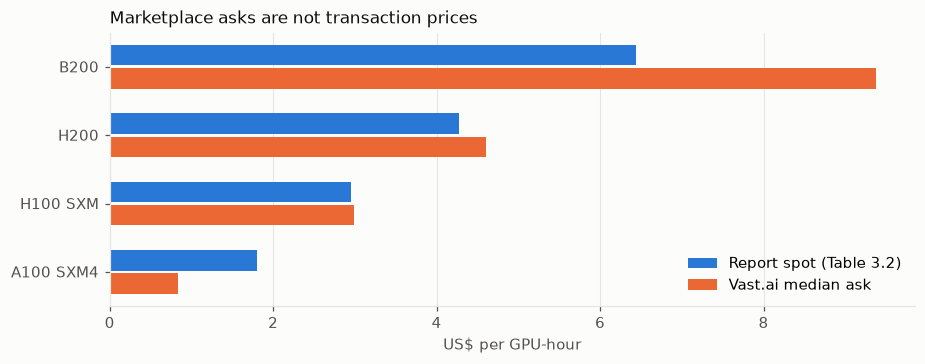

In [4]:
names = list(REPORT_SPOT)
y = np.arange(len(names))
fig, ax = plt.subplots()
ax.barh(y - 0.17, [REPORT_SPOT[n] for n in names], height=0.3, color=BLUE, label="Report spot (Table 3.2)")
ax.barh(y + 0.17, [vast[n][0] for n in names], height=0.3, color=ORANGE, label="Vast.ai median ask")
ax.set_yticks(y, names); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("US$ per GPU-hour"); ax.set_title("Marketplace asks are not transaction prices"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**What this shows.** Asks on a thin marketplace can sit far from a composite spot index in either direction. Vast.ai's B200 book holds only a handful of offers. This is exactly why the report wants TCPI built from *settled volume*: a quote is an opinion, a settled trade is a fact.

---
## 2. The cost model: a defensible opening price

**The mechanism.** A new marketplace has no trades, so it has no market price. The report seeds Phase 1 with a bottom-up cost stack: hardware amortization, power, facility, network, margin, VAT and a local premium (Table 3.4). A GPU-hour is treated like a megawatt-hour, a perishable flow, which is why utilization matters so much: an idle hour earns nothing and cannot be stored.

PASS  reproduces the report's US$3.68 floor: 3.6804
PASS  reproduces the report's NT$114.10: 114.09
PASS  reproduces the 3-year case of US$4.60: 4.5994
PASS  the floor sits inside the 1-3 year term range of US$3.42-4.32


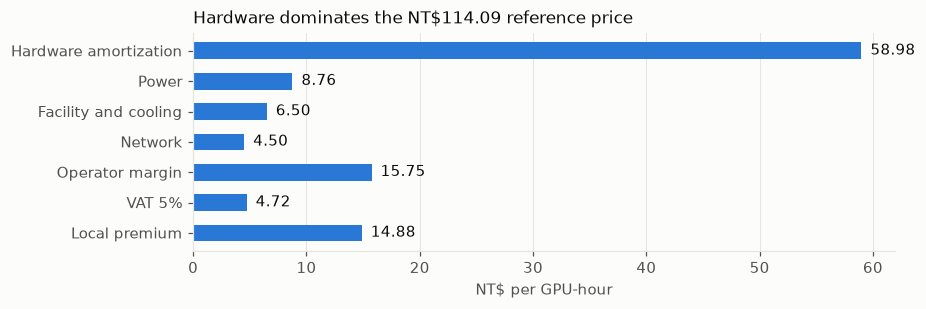

At live USD/TWD 32.84: NT$119.17 (+4.45%), US$3.63 (-1.41%)
Pantera: US$1.41/hr calendar = US$1.88/hr at 75% utilization, vs Petahour US$1.90/hr
PASS  the two models agree within US$0.03 once conventions are aligned


In [5]:
def cost_stack(capex=50_000, life_years=4, utilization=0.75, kw=1.7875, pue=1.4, tariff=3.5,
               facility=6.5, network=4.5, margin=0.20, vat=0.05, premium=0.15, fx=31.0):
    amort = capex / (life_years * 8760 * utilization) * fx    # hardware is priced in USD
    power = kw * pue * tariff                                 # power is priced in NT$
    subtotal = amort + power + facility + network
    pre_vat = subtotal * (1 + margin)
    domestic = pre_vat * (1 + vat)
    reference = domestic * (1 + premium)
    return {"Hardware amortization": amort, "Power": power, "Facility and cooling": facility, "Network": network,
            "Operator margin": subtotal * margin, "VAT 5%": pre_vat * vat, "Local premium": domestic * premium,
            "_ntd": reference, "_usd": reference / fx}

report_case = cost_stack()
three_year = cost_stack(life_years=3)
live_case = cost_stack(fx=fx)

check(abs(report_case["_usd"] - 3.68) < 0.005, f"reproduces the report's US$3.68 floor: {report_case['_usd']:.4f}")
check(abs(report_case["_ntd"] - 114.10) < 0.02, f"reproduces the report's NT$114.10: {report_case['_ntd']:.2f}")
check(abs(three_year["_usd"] - 4.60) < 0.005, f"reproduces the 3-year case of US$4.60: {three_year['_usd']:.4f}")
check(3.42 <= report_case["_usd"] <= 4.32, "the floor sits inside the 1-3 year term range of US$3.42-4.32")

parts = {k: v for k, v in report_case.items() if not k.startswith("_")}
fig, ax = plt.subplots(figsize=(8.5, 2.9))
ax.barh(list(parts), list(parts.values()), height=0.55, color=BLUE)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("NT$ per GPU-hour"); ax.set_title(f"Hardware dominates the NT${report_case['_ntd']:.2f} reference price")
for i, v in enumerate(parts.values()):
    ax.text(v + 0.8, i, f"{v:.2f}", va="center", color=INK)
plt.tight_layout(); plt.show()

print(f"At live USD/TWD {fx:.2f}: NT${live_case['_ntd']:.2f} ({live_case['_ntd'] / report_case['_ntd'] - 1:+.2%}), "
      f"US${live_case['_usd']:.2f} ({live_case['_usd'] / report_case['_usd'] - 1:+.2%})")
REFERENCE = round(live_case["_usd"], 2)

# Independent cross-check against Pantera's US model (C2 memo): same 8-GPU HGX B200 hardware.
pantera_calendar = 61_853 / 43_800                 # US$61,853 per GPU over 5 calendar years
pantera_at_petahour = pantera_calendar / 0.75           # restated on Petahour's 75% utilization
petahour_amort = report_case["Hardware amortization"] / 31.0
print(f"Pantera: US${pantera_calendar:.2f}/hr calendar = US${pantera_at_petahour:.2f}/hr at 75% utilization, vs Petahour US${petahour_amort:.2f}/hr")
check(abs(pantera_at_petahour - petahour_amort) < 0.03, "the two models agree within US$0.03 once conventions are aligned")

**A finding worth noting.** The report fixes the exchange rate at NT$31.00. Hardware is a dollar cost and power is an NT$ cost, so FX does not cancel out. At today's rate the NT$ reference moves by several percent, which is why the PoC takes FX as a live input.

**Spreads.** Table 3.5 sets bid/ask by liquidity tier: Tier 1 (B200) 2–5%, Tier 2 (H200, H100, A100) 5–8%, Tier 3 (MI300X, NVL72, Rubin) 8–15%.

---
## 3. Who may trade, and what they may sell

**The mechanism.** Public blockchains are pseudonymous, but every participant must be screened for export-control risk: the US EAR today, and Taiwan's controls as they stand (the Foreign Trade Act amendment some papers cite is still a pending bill). The report's answer is *decentralized execution, permissioned access*: screening happens off-chain, and only a pass/fail flag reaches the chain. No personal data goes on-chain.

Hardware cannot self-certify either. A **Compute Passport** (think bill of lading) records what a host is. It needs signatures from an M-of-N **verifier federation**: Petahour, NCHC, ODM partners and an auditor. Here that is 2-of-3, using real ECDSA.

The rule that signers must arrive in ascending order looks fussy, but it is a neat trick: it makes it impossible to pad a quorum by repeating one signature, without needing any storage.

In [6]:
def wallet(name):
    '''Deterministic demo wallet. These are throwaway keys and hold nothing.'''
    return Account.from_key(keccak(text="petahour-mini-" + name))

DENIED_PARTIES = {"shadow compute trading ltd"}                # fictional
RESTRICTED_COUNTRIES = {"CN", "RU", "IR", "KP", "SY"}          # illustrative subset, not a compliance list

def screen(legal_name, country):
    hits = []
    if legal_name.lower() in DENIED_PARTIES: hits.append("DENIED_PARTY")
    if country in RESTRICTED_COUNTRIES: hits.append("EAR_COUNTRY_GROUP_D5")
    return {"decision": "DENIED" if hits else "CLEAR", "hits": hits}

class MemberRegistry:
    '''On-chain state is one flag per wallet. Names and files stay off-chain.'''
    def __init__(self): self.eligible = {}
    def enroll(self, address, legal_name, country):
        result = screen(legal_name, country)
        if result["decision"] == "CLEAR":
            self.eligible[address] = True
        return result
    def freeze(self, address): self.eligible[address] = False
    def is_eligible(self, address): return self.eligible.get(address, False)

class Federation:
    def __init__(self, members, threshold):
        self.members, self.threshold = members, threshold
        self.signers = {m.address for m in members}
    def sign(self, digest, count=None):
        chosen = sorted(self.members, key=lambda a: int(a.address, 16))[: count or self.threshold]
        return [a.sign_message(encode_defunct(primitive=digest)).signature for a in chosen]
    def verify(self, digest, sigs):
        last = 0
        for sig in sigs:
            signer = Account.recover_message(encode_defunct(primitive=digest), signature=sig)
            if signer not in self.signers or int(signer, 16) <= last:   # outsider, duplicate or unsorted
                return False
            last = int(signer, 16)
        return len(sigs) >= self.threshold

registry = MemberRegistry()
federation = Federation([wallet("fed-petahour"), wallet("fed-nchc"), wallet("fed-odm")], threshold=2)
seller, buyer, watcher = wallet("seller"), wallet("buyer"), wallet("watcher")

for who, name in [(seller, "Taoyuan ODM Rack Capacity (sim)"), (buyer, "Alpha AI Startup (sim)"), (watcher, "Independent Watchtower (sim)")]:
    check(registry.enroll(who.address, name, "TW")["decision"] == "CLEAR", f"onboarded {name}")
check(registry.enroll(wallet("x").address, "Shadow Compute Trading Ltd", "TW")["decision"] == "DENIED", "a denied party is refused")
check(not registry.is_eligible(wallet("x").address), "and its wallet is never enrolled")

passport = {"host": "tw-taoyuan-rack-01", "sku": "B200-180GB-SXM", "gpus": 8, "interconnect": "NVLink5", "pue": 1.4,
            "grid_zone": "TPC-NORTH", "sla_bps": 9990, "residency": "Taiwan (PDPA)", "security": ["ISO 27001", "SOC 2 Type II"]}
passport_hash = keccak(text=json.dumps(passport, sort_keys=True))
sigs = federation.sign(passport_hash)
check(federation.verify(passport_hash, sigs), "a 2-of-3 federation quorum approves the passport")
check(not federation.verify(passport_hash, sigs[:1]), "one signature alone is not enough")
check(not federation.verify(passport_hash, [sigs[0], sigs[0]]), "repeating one signature cannot fake a quorum")
tampered = keccak(text=json.dumps({**passport, "gpus": 800}, sort_keys=True))
check(not federation.verify(tampered, sigs), "the seller cannot inflate the GPU count after approval")

PASS  onboarded Taoyuan ODM Rack Capacity (sim)
PASS  onboarded Alpha AI Startup (sim)
PASS  onboarded Independent Watchtower (sim)
PASS  a denied party is refused
PASS  and its wallet is never enrolled
PASS  a 2-of-3 federation quorum approves the passport
PASS  one signature alone is not enough
PASS  repeating one signature cannot fake a quorum
PASS  the seller cannot inflate the GPU count after approval


---
## 4. TEE attestation: is this real hardware?

**The mechanism.** The report's hardest problem is *the oracle problem*: how does a contract know a GPU-hour was delivered? Its answer starts with NVIDIA Confidential Computing, where the silicon proves its firmware and isolation are genuine.

The real flow, mirrored here:

1. The verifier issues a fresh **nonce** (so old evidence cannot be replayed).
2. The host sends GPU evidence to **NRAS**, NVIDIA's Remote Attestation Service.
3. NRAS returns a signed **EAT token** with claims such as `x-nvidia-overall-att-result`, `eat_nonce`, `measres`, `secboot` and `dbgstat`.
4. Each federation node verifies the token against NVIDIA's public keys.

**Why step 4 cannot happen on-chain.** NVIDIA's published keys are P-384 (ES384). The EVM has no P-384 precompile, only secp256k1 and on some chains P-256, so a contract cannot check the token directly. The federation verifies it off-chain and anchors its hash. This is a design constraint the architecture must respect.

**Key binding.** Attestation proves the hardware is genuine; the telemetry key must be tied to that same attested machine. So the nonce is `keccak(teeAddress || random)`, and a token can only vouch for the key it was requested for.

*Simulated here: there is no GPU, and "NRAS" is a local class. The tokens are real ES384 JWTs.*

In [7]:
class MockNRAS:
    '''Local stand-in for NVIDIA's service. Tokens are genuine ES384 JWTs.'''
    def __init__(self):
        self._key = ec.generate_private_key(ec.SECP384R1())
        self.public_key = self._key.public_key()
    def attest(self, nonce_hex, evidence):
        now = int(time.time())
        ok = all(e["firmware"] == "golden" and e["cc_mode"] == "on" and e["nonce"] == nonce_hex for e in evidence)
        claims = {"iss": "https://mock-nras.petahour.local", "iat": now, "exp": now + 3600, "eat_nonce": nonce_hex,
                  "x-nvidia-overall-att-result": ok, "x-nvidia-ver": "3.0", "hwmodel": "GB100",
                  "measres": "success" if ok else "fail", "secboot": True, "dbgstat": "disabled" if ok else "enabled"}
        return jwt.encode(claims, self._key, algorithm="ES384")

class SimulatedHost:
    '''The key below would be generated inside the confidential VM and never leave it.'''
    def __init__(self, gpus=8, compromised=False):
        self._key = Account.create()
        self.tee_address = self._key.address
        self.gpus, self.compromised = gpus, compromised
    def new_nonce(self):
        random_part = secrets.token_bytes(32)
        return keccak(bytes.fromhex(self.tee_address[2:]) + random_part), random_part
    def evidence(self, nonce_hex):
        return [{"nonce": nonce_hex, "firmware": "tampered" if self.compromised else "golden",
                 "cc_mode": "off" if self.compromised else "on"} for _ in range(self.gpus)]
    def seal(self, digest):
        return self._key.sign_message(encode_defunct(primitive=digest)).signature

def verify_token(token, nonce, random_part, tee_address, nras):
    '''What each federation node runs. Returns the claims, or raises with the reason.'''
    claims = jwt.decode(token, nras.public_key, algorithms=["ES384"], options={"verify_aud": False})
    if claims["eat_nonce"] != nonce.hex(): raise ValueError("stale or replayed token")
    if keccak(bytes.fromhex(tee_address[2:]) + random_part) != nonce: raise ValueError("token is not bound to this key")
    if not claims["x-nvidia-overall-att-result"]: raise ValueError("hardware failed attestation")
    return claims

nras = MockNRAS()
host = SimulatedHost()
nonce, random_part = host.new_nonce()
token = nras.attest(nonce.hex(), host.evidence(nonce.hex()))
print("header:", jwt.get_unverified_header(token))
claims = verify_token(token, nonce, random_part, host.tee_address, nras)
print("claims:", {k: claims[k] for k in ("x-nvidia-overall-att-result", "measres", "secboot", "dbgstat", "hwmodel")})
check(claims["x-nvidia-overall-att-result"], "a genuine host passes, with a real ES384 signature check")

def refused(fn, *args):
    try: fn(*args); return None
    except Exception as exc: return type(exc).__name__ + ": " + str(exc)

rogue = SimulatedHost(compromised=True)
n2, r2 = rogue.new_nonce()
reason = refused(verify_token, nras.attest(n2.hex(), rogue.evidence(n2.hex())), n2, r2, rogue.tee_address, nras)
check(reason and "failed attestation" in reason, f"a host with tampered firmware is refused -> {reason}")
impostor = SimulatedHost()
reason = refused(verify_token, token, nonce, random_part, impostor.tee_address, nras)
check(reason and "not bound" in reason, f"a stolen token cannot vouch for another key -> {reason}")
reason = refused(verify_token, token[:-6] + "AAAAAA", nonce, random_part, host.tee_address, nras)
check(reason is not None, f"a tampered token fails its signature -> {reason}")

attested_until = {}   # the on-chain record: passport id -> expiry
PASSPORT_ID = 1
ATTESTATION_DIGEST = keccak(text=f"attest:{PASSPORT_ID}:{keccak(text=token).hex()}")
check(federation.verify(ATTESTATION_DIGEST, federation.sign(ATTESTATION_DIGEST)), "the federation anchors the token hash, not the token")

header: {'alg': 'ES384', 'typ': 'JWT'}
claims: {'x-nvidia-overall-att-result': True, 'measres': 'success', 'secboot': True, 'dbgstat': 'disabled', 'hwmodel': 'GB100'}
PASS  a genuine host passes, with a real ES384 signature check
PASS  a host with tampered firmware is refused -> ValueError: hardware failed attestation
PASS  a stolen token cannot vouch for another key -> ValueError: token is not bound to this key
PASS  a tampered token fails its signature -> InvalidSignatureError: Signature verification failed
PASS  the federation anchors the token hash, not the token


**A caveat for production.** A GPU attestation shows that a genuine GPU in confidential-computing mode is reachable. On its own it does not show that GPU is bound to a particular confidential VM. Production needs *dual attestation*: a CPU TEE quote (Intel TDX or AMD SEV-SNP) that carries the telemetry key and the GPU nonce together. Attestation also proves *authenticity*, not *hours delivered*, which is why §7 and §8 are still needed.

---
## 5. Price discovery: fast, off-chain, and unable to steal

**The mechanism.** Table 4.2 ranks blockchain speed as the *easiest* problem, because a GPU-hour takes an hour to deliver no matter how fast the chain is. Matching therefore stays off-chain, where it can run in microseconds.

Two venues, as the report specifies:

- **Day-ahead auction**: everyone trades at one uniform price, chosen to maximise matched volume (like the Taipower wholesale market).
- **Intraday CLOB**: a continuous central limit order book with price-time priority.

**The important design choice.** Clients *sign* their orders. The matcher can propose a trade, but it cannot change a client's limit without breaking the signature, and the contract re-checks everything (§6). A compromised matcher can fail to match; it cannot trade outside what a client signed. Matching also respects attributes a normal engine does not model, such as SLA tier and grid zone.

cleared 576 GPU-hours at US$3.575 in 181 microseconds
PASS  every fill respects both signed limits
PASS  the auction is uniform price: everyone pays the same


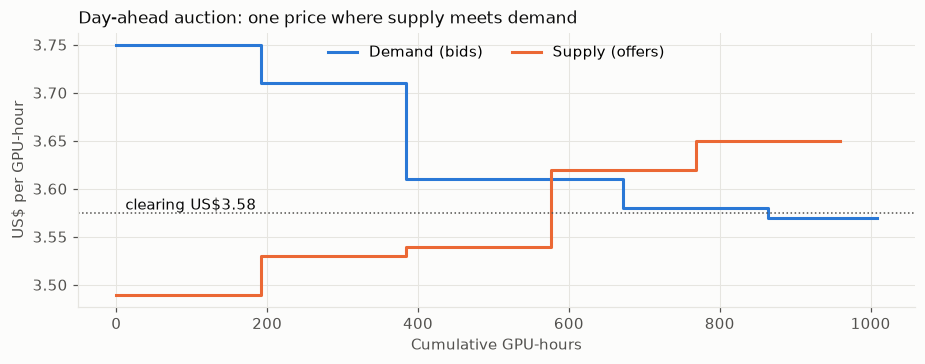

In [8]:
@dataclass
class Order:
    maker: str; is_buy: bool; qty: int; limit: float; min_sla: int = 0; zone: str = "any"
    host_sla: int = 0; host_zone: str = ""; remaining: int = -1; sig: bytes = b""
    salt: int = field(default_factory=lambda: secrets.randbits(64))   # two identical orders stay distinct
    def __post_init__(self):
        if self.remaining < 0: self.remaining = self.qty
    def digest(self):
        return keccak(text=f"{self.maker}|{self.is_buy}|{self.qty}|{self.limit}|{self.min_sla}|{self.zone}|{self.salt}")

def signed(account, **kw):
    order = Order(maker=account.address, **kw)
    order.sig = account.sign_message(encode_defunct(primitive=order.digest())).signature
    return order

def compatible(bid, ask):
    return ask.host_sla >= bid.min_sla and (bid.zone == "any" or bid.zone == ask.host_zone)

def clearing_price(bids, asks):
    best, tied = 0, []
    for p in sorted({o.limit for o in bids + asks}):
        volume = min(sum(o.remaining for o in bids if o.limit >= p), sum(o.remaining for o in asks if o.limit <= p))
        if volume > best: best, tied = volume, [p]
        elif volume == best and volume > 0: tied.append(p)
    return ((tied[0] + tied[-1]) / 2, best) if tied else (None, 0)

def auction(orders):
    bids = sorted((o for o in orders if o.is_buy), key=lambda o: -o.limit)
    asks = sorted((o for o in orders if not o.is_buy), key=lambda o: o.limit)
    price, _ = clearing_price(bids, asks)
    fills = []
    for bid in (b for b in bids if b.limit >= price):
        for ask in (a for a in asks if a.limit <= price):
            if bid.remaining and ask.remaining and compatible(bid, ask):
                qty = min(bid.remaining, ask.remaining)
                bid.remaining -= qty; ask.remaining -= qty
                fills.append((bid, ask, qty, price))
    return fills, price

rng = random.Random(SEED)
sell_side = [signed(wallet(f"s{i}"), is_buy=False, qty=192, limit=round(REFERENCE * rng.uniform(0.96, 1.02), 2), host_sla=9990, host_zone="north") for i in range(5)]
buy_side = [signed(wallet(f"b{i}"), is_buy=True, qty=rng.choice([96, 144, 192]), limit=round(REFERENCE * rng.uniform(0.98, 1.05), 2), min_sla=9990) for i in range(6)]

t0 = time.perf_counter()
curve_bids, curve_asks = sorted(buy_side, key=lambda o: -o.limit), sorted(sell_side, key=lambda o: o.limit)
fills, price = auction(buy_side + sell_side)
elapsed = (time.perf_counter() - t0) * 1e6
print(f"cleared {sum(f[2] for f in fills)} GPU-hours at US${price:.3f} in {elapsed:.0f} microseconds")
check(all(f[0].limit >= f[3] >= f[1].limit for f in fills), "every fill respects both signed limits")
check(len({f[3] for f in fills}) == 1, "the auction is uniform price: everyone pays the same")

def steps(orders):
    xs, ys, total = [0], [orders[0].limit], 0
    for o in orders:
        total += o.qty
        xs += [total]; ys += [o.limit]
    return xs, ys
fig, ax = plt.subplots()
ax.step(*steps(curve_bids), where="pre", color=BLUE, label="Demand (bids)")
ax.step(*steps(curve_asks), where="pre", color=ORANGE, label="Supply (offers)")
ax.axhline(price, color=MUTED, linewidth=1, linestyle=":")
ax.text(12, price, f"clearing US${price:.2f}", va="bottom", ha="left", color=INK)
ax.set_xlabel("Cumulative GPU-hours"); ax.set_ylabel("US$ per GPU-hour")
ax.set_title("Day-ahead auction: one price where supply meets demand"); ax.legend(loc="upper center", ncol=2)
plt.tight_layout(); plt.show()

In [9]:
class OrderBook:
    '''Continuous price-time priority. The resting order sets the trade price.'''
    def __init__(self): self.bids, self.asks = [], []
    def submit(self, order):
        fills = []
        book = self.asks if order.is_buy else self.bids
        book.sort(key=(lambda o: o.limit) if order.is_buy else (lambda o: -o.limit))  # stable: time priority kept
        for resting in list(book):
            crosses = resting.limit <= order.limit if order.is_buy else resting.limit >= order.limit
            if not crosses or not order.remaining: break
            bid, ask = (order, resting) if order.is_buy else (resting, order)
            if not compatible(bid, ask): continue
            qty = min(order.remaining, resting.remaining)
            order.remaining -= qty; resting.remaining -= qty
            fills.append((qty, resting.limit))
            if not resting.remaining: book.remove(resting)
        if order.remaining: (self.bids if order.is_buy else self.asks).append(order)
        return fills

book = OrderBook()
a1 = signed(seller, is_buy=False, qty=50, limit=3.70, host_sla=9990, host_zone="north")
a2 = signed(seller, is_buy=False, qty=50, limit=3.60, host_sla=9900, host_zone="south")
book.submit(a1); book.submit(a2)
strict = signed(buyer, is_buy=True, qty=60, limit=3.75, min_sla=9990)
fills_clob = book.submit(strict)
print("fills:", fills_clob, "| still resting:", [(o.limit, o.remaining) for o in book.asks + book.bids])
check(fills_clob == [(50, 3.70)], "attribute matching: the cheaper offer is skipped because its SLA tier is too low")
check(strict.remaining == 10, "the unfilled remainder rests on the book")

fills: [(50, 3.7)] | still resting: [(3.6, 50), (3.75, 10)]
PASS  attribute matching: the cheaper offer is skipped because its SLA tier is too low
PASS  the unfilled remainder rests on the book


---
## 6. DvP escrow: where the money actually waits

**The mechanism.** Delivery-versus-Payment means neither side can walk away with both the money and the compute. When a match arrives, the contract:

1. Verifies **both client signatures** and every limit, ignoring whatever the matcher claims.
2. Checks the host's attestation and that the **same GPU-hour has not been sold twice**.
3. Locks the buyer's payment and its share of the fee, and the seller's collateral (20% of notional).

From there a trade moves through a small state machine:

```
Open --claim--> Claimed --T+1 window passes--> Settled
                   |
               challenge --> Challenged --valid zk proof--> Settled (challenger loses bond)
                                 |
                                 '--no proof in time--> Defaulted (seller slashed)
```

**Who pays what.** These are the fees in the 6 November financial model:

- **Marketplace fee.** 2.5% of delivered value in 2027, stepping down to 1.25% by 2031. The model gives one combined rate, so the build splits it evenly: 1.25% from each side in 2027. The buyer's share is locked with its payment. The seller's comes out of its proceeds at settlement.
- **Only on what was delivered.** Both shares scale with uptime, and a default pays no fee at all.
- **Rate changes.** A trade keeps the rate it opened at, so a step-down never touches an open trade.
- **Passport fee.** US$60 per GPU a year, paid by the seller, at half price in 2027. A Passport cannot sell delivery beyond the term it has paid for.

The class below mirrors `contracts/core/DvPEscrow.sol`, including its default waterfall. The full PoC runs the same logic as real Solidity.

*Simulated: `MiniChain` is a clock and an event list, not a blockchain.*

In [10]:
HOUR, DAY = 3_600, 86_400

class Revert(Exception):
    '''What a smart contract does when a rule is broken: the whole transaction is undone.'''

class MiniChain:
    def __init__(self): self.now, self.events = 1_800_000_000, []
    def advance(self, seconds): self.now += seconds
    def emit(self, name, **kw): self.events.append((name, kw))

class Escrow:
    BUYER_FEE_BPS, SELLER_FEE_BPS = 125, 125                 # 2.5% combined in 2027
    COLLATERAL_BPS, PENALTY_BPS, REWARD_BPS, SLA_CREDIT_BPS = 2_000, 2_500, 1_000, 5_000
    PASSPORT_FEE_PER_GPU_YEAR, PASSPORT_DISCOUNT_BPS, TERM = 60.0, 5_000, 365 * DAY
    DISPUTE_WINDOW, RESPONSE_WINDOW, BOND = DAY, 6 * HOUR, 100.0

    def __init__(self, chain, registry, default_fund):
        self.chain, self.registry, self.default_fund = chain, registry, default_fund
        self.free, self.trades, self.locked = {}, {}, 0.0
        self.allocated, self.filled, self.hosts = {}, {}, {}
        self.next_id, self.treasury, self.passport_fees = 1, 0.0, 0.0

    def register_host(self, passport_id, owner, tee_address, gpus, sla_bps):
        # The first year is paid from the seller's wallet at mint, outside the escrow balances.
        self.passport_fees += gpus * self.PASSPORT_FEE_PER_GPU_YEAR * (10_000 - self.PASSPORT_DISCOUNT_BPS) / 10_000
        self.hosts[passport_id] = {"owner": owner, "tee": tee_address, "gpus": gpus, "sla": sla_bps, "suspended": False,
                                   "paid_until": self.chain.now + self.TERM}

    def deposit(self, who, amount):
        if not self.registry.is_eligible(who): raise Revert(f"NotEligible({who[:8]})")
        self.free[who] = self.free.get(who, 0.0) + amount

    def _lock(self, who, amount):
        if self.free.get(who, 0.0) < amount: raise Revert("InsufficientFree")
        self.free[who] -= amount; self.locked += amount

    def match(self, bid, ask, qty, price, passport_id, start, hours=24):
        # Every check is repeated here on purpose: the matcher is not trusted.
        for order in (bid, ask):
            signer = Account.recover_message(encode_defunct(primitive=order.digest()), signature=order.sig)
            if signer != order.maker: raise Revert("BadSignature")
            if not self.registry.is_eligible(order.maker): raise Revert("NotEligible")
            if self.filled.get(order.digest(), 0) + qty > order.qty: raise Revert("Overfill")
        if price > bid.limit or price < ask.limit: raise Revert("PriceOutsideLimits")
        host = self.hosts[passport_id]
        if host["suspended"]: raise Revert("NotAttestedForWindow")
        if host["owner"] != ask.maker: raise Revert("PassportConstraint")
        if host["paid_until"] < start + hours * HOUR: raise Revert("PassportFeeDue")
        gpus = -(-qty // hours)                                  # GPUs per hour, rounded up
        for h in range(start // HOUR, start // HOUR + hours):
            if self.allocated.get((passport_id, h), 0) + gpus > host["gpus"]: raise Revert(f"Oversold(hour {h})")
        notional = qty * price
        buyer_fee = notional * self.BUYER_FEE_BPS / 10_000
        seller_fee = notional * self.SELLER_FEE_BPS / 10_000     # taken from proceeds, so not locked now
        collateral = notional * self.COLLATERAL_BPS / 10_000
        self._lock(bid.maker, notional + buyer_fee); self._lock(ask.maker, collateral)
        for h in range(start // HOUR, start // HOUR + hours):
            self.allocated[(passport_id, h)] = self.allocated.get((passport_id, h), 0) + gpus
        for order in (bid, ask):
            self.filled[order.digest()] = self.filled.get(order.digest(), 0) + qty
        trade_id = self.next_id; self.next_id += 1
        self.trades[trade_id] = dict(buyer=bid.maker, seller=ask.maker, passport=passport_id, qty=qty, price=price, notional=notional,
                                     buyer_fee=buyer_fee, seller_fee=seller_fee, collateral=collateral, start=start, end=start + hours * HOUR, status="Open")
        return trade_id

    def claim(self, trade_id, uptime_bps, root, commitment, seal):
        t = self.trades[trade_id]
        if t["status"] != "Open": raise Revert("WrongStatus")
        if self.chain.now < t["end"]: raise Revert("TooEarly")
        digest = seal_digest(trade_id, t["passport"], root, commitment)
        if Account.recover_message(encode_defunct(primitive=digest), signature=seal) != self.hosts[t["passport"]]["tee"]:
            raise Revert("InvalidSeal")
        t.update(status="Claimed", uptime=uptime_bps, root=root, commitment=commitment, claimed_at=self.chain.now)

    def finalize(self, trade_id):
        t = self.trades[trade_id]
        if t["status"] != "Claimed": raise Revert("WrongStatus")
        if self.chain.now < t["claimed_at"] + self.DISPUTE_WINDOW: raise Revert("TooEarly")
        self._settle(t)

    def challenge(self, trade_id, who):
        t = self.trades[trade_id]
        if t["status"] != "Claimed": raise Revert("WrongStatus")
        if not self.registry.is_eligible(who): raise Revert("NotEligible")
        if self.chain.now >= t["claimed_at"] + self.DISPUTE_WINDOW: raise Revert("TooLate")
        self._lock(who, self.BOND)
        t.update(status="Challenged", challenger=who, deadline=self.chain.now + self.RESPONSE_WINDOW)

    def respond_with_proof(self, trade_id, proof, verify):
        t = self.trades[trade_id]
        if t["status"] != "Challenged": raise Revert("WrongStatus")
        if self.chain.now > t["deadline"]: raise Revert("TooLate")
        if not verify(t, proof): raise Revert("InvalidProof")
        self.locked -= self.BOND
        self.free[t["seller"]] += self.BOND                      # a false challenger loses the bond
        self._settle(t)

    def resolve_timeout(self, trade_id):
        t = self.trades[trade_id]
        if t["status"] != "Challenged": raise Revert("WrongStatus")
        if self.chain.now <= t["deadline"]: raise Revert("TooEarly")
        self._default(t)

    def _settle(self, t):
        share = t["uptime"] / 10_000
        paid = t["notional"] * share                             # honest partial delivery is paid pro rata
        buyer_fee_due, seller_fee_due = t["buyer_fee"] * share, t["seller_fee"] * share
        credit = 0.0
        if t["uptime"] < self.hosts[t["passport"]]["sla"]:
            credit = min((t["notional"] - paid) * self.SLA_CREDIT_BPS / 10_000, t["collateral"])
        self.locked -= t["notional"] + t["buyer_fee"] + t["collateral"]
        self.free[t["seller"]] += paid - seller_fee_due + t["collateral"] - credit
        self.free[t["buyer"]] += (t["notional"] - paid) + (t["buyer_fee"] - buyer_fee_due) + credit
        self.treasury += buyer_fee_due + seller_fee_due
        t["status"] = "Settled"

    def _default(self, t):
        collateral = t["collateral"]
        reward = collateral * self.REWARD_BPS / 10_000
        penalty = t["notional"] * self.PENALTY_BPS / 10_000
        from_collateral = min(penalty, collateral - reward)
        left = collateral - reward - from_collateral
        from_fund = self.default_fund.cover(penalty - from_collateral)
        self.locked -= t["notional"] + t["buyer_fee"] + collateral + self.BOND
        self.free[t["buyer"]] += t["notional"] + t["buyer_fee"] + from_collateral + from_fund
        self.free[t["challenger"]] += self.BOND + reward
        self.default_fund.pool += left
        self.hosts[t["passport"]]["suspended"] = True
        t.update(status="Defaulted", waterfall=dict(refund=t["notional"] + t["buyer_fee"], from_collateral=from_collateral, from_fund=from_fund, reward=reward))

class DefaultFund:
    def __init__(self, pool): self.pool = pool
    def cover(self, amount):
        paid = min(amount, self.pool); self.pool -= paid
        return paid

def seal_digest(trade_id, passport_id, root, commitment):
    return keccak(text=f"seal|{trade_id}|{passport_id}|{root.hex()}|{commitment}")

chain, fund = MiniChain(), DefaultFund(25_000.0)
escrow = Escrow(chain, registry, fund)
escrow.register_host(PASSPORT_ID, seller.address, host.tee_address, gpus=8, sla_bps=9990)
check(escrow.passport_fees == 8 * 30, f"the seller paid {usd(escrow.passport_fees)} at mint: 8 GPUs at the 2027 half price of US$30")
START_FREE = {seller.address: 50_000.0, buyer.address: 100_000.0, watcher.address: 5_000.0}
for address, amount in START_FREE.items():
    escrow.deposit(address, amount)

bid = signed(buyer, is_buy=True, qty=192, limit=3.70)
ask = signed(seller, is_buy=False, qty=192, limit=3.60)
delivery_start = chain.now + HOUR

def attempt(fn, *args):
    try: fn(*args); return "accepted"
    except Revert as exc: return str(exc)

r = attempt(escrow.match, bid, ask, 192, 3.71, PASSPORT_ID, delivery_start)
check(r == "PriceOutsideLimits", f"a compromised matcher cannot overcharge -> {r}")
forged = signed(seller, is_buy=True, qty=192, limit=3.70); forged.maker = buyer.address
r = attempt(escrow.match, forged, ask, 192, 3.65, PASSPORT_ID, delivery_start)
check(r == "BadSignature", f"a matcher cannot forge a client's order -> {r}")

trade_id = escrow.match(bid, ask, 192, 3.65, PASSPORT_ID, delivery_start)
t = escrow.trades[trade_id]
print(f"trade {trade_id} opened: 192 GPU-hours at US$3.65, notional {usd(t['notional'])}, seller collateral {usd(t['collateral'])}")
b2, a2 = signed(buyer, is_buy=True, qty=24, limit=3.70), signed(seller, is_buy=False, qty=24, limit=3.60)
r = attempt(escrow.match, b2, a2, 24, 3.65, PASSPORT_ID, delivery_start)
check(r.startswith("Oversold"), f"the same GPU-hour cannot be sold twice -> {r}")
check(escrow.locked == t["notional"] + t["buyer_fee"] + t["collateral"], "the buyer's payment and fee, and the seller's collateral, are locked")
b3, a3 = signed(buyer, is_buy=True, qty=192, limit=3.70), signed(seller, is_buy=False, qty=192, limit=3.60)
r = attempt(escrow.match, b3, a3, 192, 3.65, PASSPORT_ID, chain.now + 400 * DAY)
check(r == "PassportFeeDue", f"a Passport cannot sell delivery beyond its paid term -> {r}")

PASS  the seller paid 240.00 at mint: 8 GPUs at the 2027 half price of US$30
PASS  a compromised matcher cannot overcharge -> PriceOutsideLimits
PASS  a matcher cannot forge a client's order -> BadSignature
trade 1 opened: 192 GPU-hours at US$3.65, notional 700.80, seller collateral 140.16


PASS  the same GPU-hour cannot be sold twice -> Oversold(hour 500001)
PASS  the buyer's payment and fee, and the seller's collateral, are locked
PASS  a Passport cannot sell delivery beyond its paid term -> PassportFeeDue


---
## 7. Delivery: measuring and sealing the hours

**The mechanism.** Delivery is measured inside the attested machine. Each hour produces a DCGM-style record. At the end of the window the host makes **two commitments over the same data**, because two different verifiers need them:

| Commitment | Cheap for | Used by |
|---|---|---|
| keccak Merkle root | the EVM | **opML**: a buyer holding the hourly records can recompute it and re-run the check |
| SNARK-friendly hash | zero-knowledge circuits | **zkML**: the seller can prove without disclosing the records |

The sealed key signs both commitments. Without that key, no one can fabricate a seal.

**A subtle but vital split of duties.** The host seals *what it measured*. The seller then *claims* an uptime. These are separate acts, and the claim is what can be false. That is the entire reason a dispute process needs to exist.

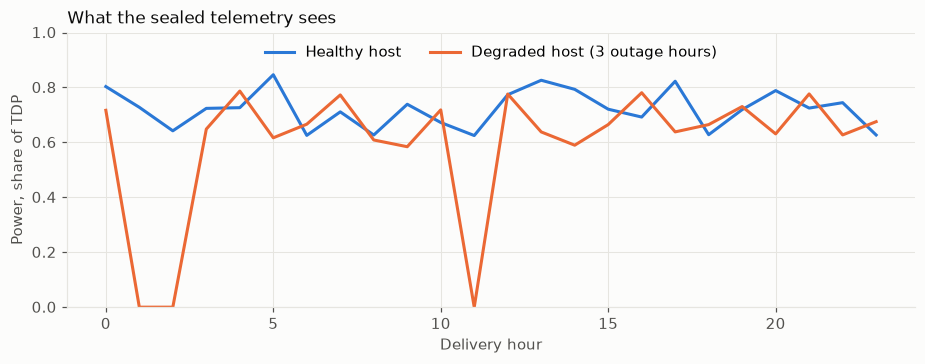

healthy features  [uptime, power, throttle] bps: [9995, 7221, 112]
degraded features [uptime, power, throttle] bps: [8745, 5963, 2195]
partial features  [uptime, power, throttle] bps: [8746, 6424, 118]
PASS  changing any hourly record changes the Merkle root


In [11]:
def simulate_telemetry(hours=24, profile="healthy", seed=0):
    rng = random.Random(seed)
    outages = set(rng.sample(range(hours), 3)) if profile in ("degraded", "partial") else set()
    rows = []
    for h in range(hours):
        up = 0.0 if h in outages else 1.0 - rng.uniform(0, 0.001)
        if profile == "degraded":
            throttle, power = rng.uniform(0.10, 0.30), rng.uniform(0.55, 0.80)
        else:
            throttle, power = rng.uniform(0.0, 0.02), rng.uniform(0.62, 0.86)
        rows.append({"hour": h, "available": round(up, 5), "power": round(power * up, 4), "throttle": round(throttle, 4)})
    return rows

def leaf(row): return keccak(text=json.dumps(row, sort_keys=True))

def merkle_root(rows):
    layer = [leaf(r) for r in rows]
    while len(layer) > 1:
        layer = [keccak(min(a, b) + max(a, b)) for a, b in zip(layer[0::2], layer[1::2] + ([layer[-1]] if len(layer) % 2 else []))]
    return layer[0]

def to_features(rows):
    '''Three integer features in basis points: uptime, power, throttle.'''
    n = len(rows)
    return [round(sum(r[k] for r in rows) / n * 10_000) for k in ("available", "power", "throttle")]

healthy, degraded = simulate_telemetry(seed=1), simulate_telemetry(profile="degraded", seed=2)
partial = simulate_telemetry(profile="partial", seed=3)   # real outages, honestly reported
fig, ax = plt.subplots()
ax.plot([r["hour"] for r in healthy], [r["power"] for r in healthy], color=BLUE, label="Healthy host")
ax.plot([r["hour"] for r in degraded], [r["power"] for r in degraded], color=ORANGE, label="Degraded host (3 outage hours)")
ax.set_xlabel("Delivery hour"); ax.set_ylabel("Power, share of TDP"); ax.set_ylim(0, 1)
ax.set_title("What the sealed telemetry sees"); ax.legend(loc="upper center", ncol=2)
plt.tight_layout(); plt.show()

print("healthy features  [uptime, power, throttle] bps:", to_features(healthy))
print("degraded features [uptime, power, throttle] bps:", to_features(degraded))
print("partial features  [uptime, power, throttle] bps:", to_features(partial))
root = merkle_root(healthy)
check(merkle_root(healthy) == root and merkle_root(healthy[:-1] + [{**healthy[-1], "power": 0.1}]) != root, "changing any hourly record changes the Merkle root")

---
## 8. opML: optimism with teeth

**The mechanism.** Verifying every delivery on-chain would be slow and costly. So the protocol is *optimistic*: a claim stands unless someone proves otherwise within the **T+1 window**.

- **T+0**: the seller claims, with a host-sealed commitment. Settlement is *provisional*.
- **T+1**: if no one challenged within 24 hours, escrow releases. This is exactly the report's settlement cycle.

This costs almost nothing when delivery is honest, which is the common case. It works because a watcher can re-execute the check cheaply off-chain, and a bond stops frivolous challenges.

**Who can actually check?** Re-execution needs the telemetry. The buyer has it, since it is their own workload's data. A third-party watcher does not, unless the buyer shares it.

In [12]:
def watchtower(rows, trade):
    '''opML re-execution: recompute what the chain says, and compare.'''
    problems = []
    if merkle_root(rows) != trade["root"]:
        problems.append("telemetry does not match the on-chain root")
    measured = to_features(rows)[0]
    if measured < trade["uptime"]:
        problems.append(f"claimed {trade['uptime'] / 100:.2f}% but measured {measured / 100:.2f}%")
    return problems

def deliver(trade_id, the_host, rows, claimed_bps=None):
    '''The host seals what it measured. The seller then asserts an uptime, which may differ.'''
    t = escrow.trades[trade_id]
    chain.advance(max(0, t["end"] - chain.now))
    feats = to_features(rows)
    salt = secrets.randbelow(2**64)
    commitment = commit_features(feats, salt)
    root = merkle_root(rows)
    seal = the_host.seal(seal_digest(trade_id, t["passport"], root, commitment))
    escrow.claim(trade_id, feats[0] if claimed_bps is None else claimed_bps, root, commitment, seal)
    return feats, salt

---
## 9. zkML: proving delivery without showing the telemetry

### Why zkML is used here, and where it is not

The report rejects zkML for metering, and rightly: proving a real GPU workload costs **1,000x to 10,000x** native runtime. Table 4.3 is clear about this. So this architecture **never** uses zkML to meter GPU-hours.

It has one narrow job, on the **dispute path only**, over a **tiny** model:

> "The approved SLA model, run on the telemetry the host sealed, passes at the uptime I claimed."

Why bother, given opML already exists? **Privacy.** Telemetry can reveal a tenant's workload pattern, which matters under PDPA and to any buyer running proprietary training. With opML, resolving a dispute means disclosing the data. With zkML, the seller wins without revealing a single record, and no human or federation has to rule.

### Each mechanism answers a different question

| Layer | The question it answers | Cost |
|---|---|---|
| TEE attestation | Is this real, unmodified hardware? | One-off at start-up |
| opML window | Did anyone object to this claim? | Almost free unless disputed |
| zkML | Is the disputed claim true, without showing the data? | Heavy, but rare and tiny |

### What is real below

This is a **genuine Groth16 zk-SNARK** on the BN254 curve (the curve Ethereum's precompiles support), written from scratch in about 150 lines so every step is visible. It is slow because it is pure Python. The full PoC uses `circom` and `snarkjs`, with a Poseidon hash, a neural network and an on-chain verifier.

*Toy parts here: the hash is a short MiMC-style sponge, and the trusted setup happens in this notebook, so the "toxic waste" is known. Neither is secure for production.*

### Step 1: train and quantize the model

A SNARK proves integer arithmetic over a finite field, so a floating-point model must become exact integers. Here a logistic regression over three features is scaled up and rounded.

**The model judges delivery quality only.** Uptime is checked separately, by comparing the measured value with the claim. This separation matters. If the model also demanded high uptime, a seller who honestly reported 87% after a real outage could never prove their claim, and would be slashed for telling the truth. Keeping them apart means honesty about an outage is always provable and is paid pro rata.

In [13]:
def make_data(n=6000, seed=SEED):
    rng = np.random.default_rng(seed)
    # Uptime varies freely in both classes, so the model learns to ignore it.
    good = np.column_stack([rng.integers(5000, 10001, n), rng.integers(4000, 9000, n), rng.integers(0, 400, n)])
    bad = good.copy()
    pick = rng.integers(0, 2, n)
    bad[pick == 0, 1] = rng.integers(200, 2500, (pick == 0).sum())
    bad[pick == 1, 2] = rng.integers(900, 6000, (pick == 1).sum())
    return np.vstack([good, bad]), np.r_[np.ones(n), np.zeros(n)]

X, y = make_data()
clf = LogisticRegression(C=100, max_iter=2000).fit(X / 10_000, y)

SCALE = 64
OFFSET = 1 << 30                                      # keeps the public threshold a positive number
W = [int(round(w * SCALE)) for w in clf.coef_[0]]     # integer weights, may be negative
B = int(round(clf.intercept_[0] * SCALE * 10_000)) + OFFSET
THRESHOLD = OFFSET

def score(features): return sum(w * x for w, x in zip(W, features)) + B
def passes(features): return score(features) >= THRESHOLD

accuracy = np.mean([passes([int(v) for v in row]) == bool(label) for row, label in zip(X[:3000], y[:3000])])
print(f"weights {W}, float accuracy {clf.score(X / 10_000, y):.3f}, integer accuracy on a sample {accuracy:.3f}")
check(passes(to_features(healthy)) and not passes(to_features(degraded)), "the integer model passes healthy telemetry and fails degraded")
check(passes(to_features(partial)), "an honest outage still passes: quality was fine for the hours delivered")

weights [-2, 1944, -9778], float accuracy 0.993, integer accuracy on a sample 0.993
PASS  the integer model passes healthy telemetry and fails degraded
PASS  an honest outage still passes: quality was fine for the hours delivered


### Step 2: turn the statement into a circuit

A SNARK proves a list of constraints of the form `a × b = c` over a field (an R1CS). The tracer below runs the calculation once and records every multiplication as a constraint. The circuit enforces:

1. each feature fits in 14 bits (so nothing can wrap around the field);
2. the private features and salt hash to the **public commitment** the host sealed;
3. `score - threshold` is non-negative;
4. measured uptime is at least the **public claimed uptime**;
5. the proof is bound to one **trade id**, so it cannot be replayed.

"Non-negative" is the clever bit. In a finite field a negative number wraps to something huge, which has no valid 31-bit decomposition. So a false claim has **no valid witness at all**. The prover is not forbidden from lying; lying is mathematically impossible.

In [14]:
from py_ecc.optimized_bn128 import G1, G2, add, multiply, neg, pairing, curve_order as R

class LC:
    '''A linear combination of circuit variables: {variable index: coefficient}.'''
    def __init__(self, terms=None): self.t = dict(terms or {})
    def __add__(self, o):
        out = dict(self.t)
        for k, v in o.t.items(): out[k] = (out.get(k, 0) + v) % R
        return LC(out)
    def __sub__(self, o): return self + o.scale(-1)
    def scale(self, k): return LC({i: (c * k) % R for i, c in self.t.items()})

ONE = LC({0: 1})   # variable 0 is the constant 1

class Tracer:
    def __init__(self): self.w, self.names, self.rows = [1], ["1"], []
    def var(self, value, name):
        self.w.append(value % R); self.names.append(name)
        return LC({len(self.w) - 1: 1})
    def val(self, lc): return sum(c * self.w[i] for i, c in lc.t.items()) % R
    def mul(self, a, b, name="m"):
        out = self.var(self.val(a) * self.val(b), name)
        self.rows.append((a, b, out))
        return out
    def equal(self, a, b): self.rows.append((a, ONE, b))
    def bits(self, x, n):
        '''Range check: x must decompose into n bits.'''
        v, acc = self.val(x), LC()
        for i in range(n):
            b = self.var((v >> i) & 1, f"bit{i}")
            self.rows.append((b, b - ONE, LC()))       # b * (b - 1) = 0, so b is 0 or 1
            acc = acc + b.scale(1 << i)
        self.equal(acc, x)
    def satisfied(self):
        return all(self.val(a) * self.val(b) % R == self.val(c) for a, b, c in self.rows)

ROUND_CONSTANTS = [int.from_bytes(keccak(text=f"petahour-mimc-{i}"), "big") % R for i in range(2)]

def commit_features(features, salt):
    '''Toy MiMC-style sponge. Native version, must match the in-circuit version exactly.'''
    h = 0
    for value in list(features) + [salt]:
        for rc in ROUND_CONSTANTS:
            h = pow((h + value + rc) % R, 5, R)
    return h

def delivery_circuit(public, private):
    t = Tracer()
    # Public inputs come first: these are all the verifier ever sees.
    commitment = t.var(public["commitment"], "commitment")
    threshold = t.var(public["threshold"], "threshold")
    claimed = t.var(public["claimed_uptime"], "claimed_uptime")
    trade = t.var(public["trade_id"], "trade_id")
    t.n_public = 4
    # Private inputs: the telemetry never leaves the prover.
    x = [t.var(v, f"x{i}") for i, v in enumerate(private["features"])]
    salt = t.var(private["salt"], "salt")

    for xi in x:
        t.bits(xi, 14)                                               # (1)
    h = LC()
    for value in x + [salt]:                                         # (2)
        for rc in ROUND_CONSTANTS:
            s = h + value + ONE.scale(rc)
            s2 = t.mul(s, s); s4 = t.mul(s2, s2); h = t.mul(s4, s)
    t.equal(h, commitment)
    total = ONE.scale(B)                                             # (3)
    for w, xi in zip(W, x):
        total = total + xi.scale(w)
    t.bits(total - threshold, 31)
    t.bits(x[0] - claimed, 14)                                       # (4)
    t.mul(trade, trade, "binding")                                   # (5)
    return t

def witness_for(features, salt, claimed, trade_id):
    public = {"commitment": commit_features(features, salt), "threshold": THRESHOLD, "claimed_uptime": claimed, "trade_id": trade_id}
    return delivery_circuit(public, {"features": features, "salt": salt}), public

sample_features = to_features(healthy)
circuit, public = witness_for(sample_features, 12345, sample_features[0], 1)
print(f"{len(circuit.rows)} constraints, {len(circuit.w)} variables ({circuit.n_public} public)")
check(circuit.satisfied(), "honest telemetry satisfies every constraint")
false_claim, _ = witness_for(sample_features, 12345, sample_features[0] + 1, 1)
check(not false_claim.satisfied(), "claiming even 0.01% more uptime than measured has no valid witness")
bad_features = to_features(degraded)
check(not witness_for(bad_features, 12345, bad_features[0], 1)[0].satisfied(), "poor-quality telemetry has no valid witness at any claim")
partial_features = to_features(partial)
check(witness_for(partial_features, 12345, partial_features[0], 1)[0].satisfied(), "an honest partial claim does have a valid witness")
check(not witness_for(partial_features, 12345, 10_000, 1)[0].satisfied(), "the same telemetry cannot be rounded up to 100%")

118 constraints, 121 variables (4 public)
PASS  honest telemetry satisfies every constraint
PASS  claiming even 0.01% more uptime than measured has no valid witness
PASS  poor-quality telemetry has no valid witness at any claim
PASS  an honest partial claim does have a valid witness
PASS  the same telemetry cannot be rounded up to 100%


### Step 3: Groth16 from first principles

The constraints become polynomials (a *QAP*): if every constraint holds, one polynomial divides another exactly. Groth16 lets a prover show that divisibility using three curve points, checked by a single pairing equation:

$$e(A, B) = e(\alpha, \beta) \cdot e(\textstyle\sum_i x_i\, IC_i, \gamma) \cdot e(C, \delta)$$

The trusted setup hides a secret point $\tau$ inside curve points. Anyone who kept $\tau$ could forge proofs, which is why it is called toxic waste and why production uses a multi-party ceremony.

In [15]:
def inv(a): return pow(a, R - 2, R)

def poly_mul(a, b):
    out = [0] * (len(a) + len(b) - 1)
    for i, x in enumerate(a):
        if x:
            for j, y in enumerate(b):
                out[i + j] = (out[i + j] + x * y) % R
    return out

def poly_eval(p, x):
    acc = 0
    for c in reversed(p): acc = (acc * x + c) % R
    return acc

def poly_divmod(num, den):
    num, q = list(num), [0] * (len(num) - len(den) + 1)
    lead = inv(den[-1])
    for i in range(len(q) - 1, -1, -1):
        q[i] = num[i + len(den) - 1] * lead % R
        if q[i]:
            for j, d in enumerate(den):
                num[i + j] = (num[i + j] - q[i] * d) % R
    return q, num[: len(den) - 1]

class QAP:
    '''Maps constraint j to the evaluation point x = j + 1, and precomputes Lagrange bases.'''
    def __init__(self, rows, n_vars):
        self.rows, self.n_vars, self.n = rows, n_vars, len(rows)
        self.points = list(range(1, self.n + 1))
        self.Z = [1]
        for p in self.points:
            self.Z = poly_mul(self.Z, [(-p) % R, 1])
        self.basis = []
        for p in self.points:
            q, _ = poly_divmod(self.Z, [(-p) % R, 1])
            scale = inv(poly_eval(q, p))
            self.basis.append([c * scale % R for c in q])
    def at(self, tau):
        '''A_i(tau), B_i(tau), C_i(tau) for every variable.'''
        lag = [poly_eval(b, tau) for b in self.basis]
        A, Bv, C = ([0] * self.n_vars for _ in range(3))
        for j, (a, b, c) in enumerate(self.rows):
            for vec, lc in ((A, a), (Bv, b), (C, c)):
                for i, coeff in lc.t.items():
                    vec[i] = (vec[i] + coeff * lag[j]) % R
        return A, Bv, C
    def interpolate(self, values):
        out = [0] * self.n
        for y, b in zip(values, self.basis):
            if y:
                for k, c in enumerate(b):
                    out[k] = (out[k] + y * c) % R
        return out

def msm(points, scalars, zero):
    acc = zero
    for p, s in zip(points, scalars):
        if s % R: acc = add(acc, multiply(p, s % R))
    return acc

Z1, Z2 = multiply(G1, R), multiply(G2, R)   # identity elements

def setup(circuit):
    '''The trusted setup. tau, alpha, beta, gamma and delta are the toxic waste.'''
    qap = QAP(circuit.rows, len(circuit.w))
    tau, alpha, beta, gamma, delta = (secrets.randbelow(R - 1) + 1 for _ in range(5))
    A, Bv, C = qap.at(tau)
    n_pub = circuit.n_public + 1          # the constant 1 counts as public
    ig, idl = inv(gamma), inv(delta)
    mixed = [(beta * A[i] + alpha * Bv[i] + C[i]) % R for i in range(qap.n_vars)]
    z_tau = poly_eval(qap.Z, tau)
    return {
        "qap": qap, "n_pub": n_pub,
        "alpha1": multiply(G1, alpha), "beta1": multiply(G1, beta), "delta1": multiply(G1, delta),
        "beta2": multiply(G2, beta), "gamma2": multiply(G2, gamma), "delta2": multiply(G2, delta),
        "A1": [multiply(G1, a) if a else Z1 for a in A], "B1": [multiply(G1, b) if b else Z1 for b in Bv],
        "B2": [multiply(G2, b) if b else Z2 for b in Bv],
        "IC": [multiply(G1, m * ig % R) if m else Z1 for m in mixed[:n_pub]],
        "L": [multiply(G1, m * idl % R) if m else Z1 for m in mixed[n_pub:]],
        "H": [multiply(G1, pow(tau, k, R) * z_tau * idl % R) for k in range(qap.n - 1)],
    }

def prove(pk, circuit):
    if not circuit.satisfied():
        raise ValueError("no valid witness: this claim cannot be proven")
    qap, w = pk["qap"], circuit.w
    a_eval = [circuit.val(a) for a, _, _ in circuit.rows]
    b_eval = [circuit.val(b) for _, b, _ in circuit.rows]
    c_eval = [circuit.val(c) for _, _, c in circuit.rows]
    pa, pb, pc = qap.interpolate(a_eval), qap.interpolate(b_eval), qap.interpolate(c_eval)
    numerator = poly_mul(pa, pb)
    for i, c in enumerate(pc):
        numerator[i] = (numerator[i] - c) % R
    h, remainder = poly_divmod(numerator, qap.Z)
    assert not any(remainder), "the QAP must divide exactly when the witness is valid"
    r, s = secrets.randbelow(R), secrets.randbelow(R)      # these make the proof zero-knowledge
    A = add(add(pk["alpha1"], msm(pk["A1"], w, Z1)), multiply(pk["delta1"], r))
    B2 = add(add(pk["beta2"], msm(pk["B2"], w, Z2)), multiply(pk["delta2"], s))
    B1 = add(add(pk["beta1"], msm(pk["B1"], w, Z1)), multiply(pk["delta1"], s))
    C = msm(pk["L"], w[pk["n_pub"]:], Z1)
    C = add(C, msm(pk["H"], h, Z1))
    C = add(add(C, multiply(A, s)), multiply(B1, r))
    C = add(C, neg(multiply(pk["delta1"], r * s % R)))
    return {"A": A, "B": B2, "C": C}

def verify(pk, public_inputs, proof):
    '''The whole of verification: one linear combination and one pairing equation.'''
    acc = pk["IC"][0]
    for point, x in zip(pk["IC"][1:], public_inputs):
        acc = add(acc, multiply(point, x % R))
    left = pairing(proof["B"], proof["A"])
    right = pairing(pk["beta2"], pk["alpha1"]) * pairing(pk["gamma2"], acc) * pairing(pk["delta2"], proof["C"])
    return left == right

t0 = time.perf_counter(); pk = setup(circuit); setup_s = time.perf_counter() - t0
print(f"trusted setup: {setup_s:.1f}s")

trusted setup: 7.5s


In [16]:
def public_list(p): return [p["commitment"], p["threshold"], p["claimed_uptime"], p["trade_id"]]

t0 = time.perf_counter(); proof = prove(pk, circuit); prove_s = time.perf_counter() - t0
t0 = time.perf_counter(); ok = verify(pk, public_list(public), proof); verify_s = time.perf_counter() - t0
print(f"proof generated in {prove_s:.1f}s, verified in {verify_s:.1f}s")
print("everything the verifier sees:", {k: (str(v)[:18] + "..." if k == "commitment" else v) for k, v in public.items()})
check(ok, "a real Groth16 proof verifies with the pairing equation")
check(sample_features[1] not in public_list(public) and sample_features[2] not in public_list(public), "power and throttle telemetry are not among the public inputs")

other = dict(public, trade_id=2)
check(not verify(pk, public_list(other), proof), "the same proof fails on a different trade: no replay")
higher = dict(public, claimed_uptime=public["claimed_uptime"] + 1)
check(not verify(pk, public_list(higher), proof), "the same proof fails for a higher uptime claim")
forged_proof = dict(proof, A=add(proof["A"], G1))
check(not verify(pk, public_list(public), forged_proof), "a tampered proof fails")
try:
    prove(pk, witness_for(bad_features, 1, bad_features[0], 1)[0]); proved = True
except ValueError as exc:
    proved = False; print("prover says:", exc)
check(not proved, "degraded telemetry cannot be proven at all")

proof generated in 2.3s, verified in 1.6s
everything the verifier sees: {'commitment': '200369044305579682...', 'threshold': 1073741824, 'claimed_uptime': 9995, 'trade_id': 1}
PASS  a real Groth16 proof verifies with the pairing equation
PASS  power and throttle telemetry are not among the public inputs


PASS  the same proof fails on a different trade: no replay


PASS  the same proof fails for a higher uptime claim


PASS  a tampered proof fails
prover says: no valid witness: this claim cannot be proven
PASS  degraded telemetry cannot be proven at all


### Step 4: why this stays on the dispute path

A quick measurement makes the report's point concrete. Note this compares pure Python, which exaggerates the gap; production provers are vastly faster (the full PoC proves 2,259 constraints in roughly half a second). The conclusion still holds: proving costs many orders of magnitude more than computing, so it suits one tiny calculation in a rare dispute, and not every hour of a real GPU workload.

In [17]:
reps = 200_000
t0 = time.perf_counter()
for _ in range(reps): score(sample_features)
native_s = (time.perf_counter() - t0) / reps
print(f"native inference: {native_s * 1e6:.2f} microseconds")
print(f"proving the same three-weight model: {prove_s:.1f} s, about {prove_s / native_s:,.0f}x slower here")
print("The report's 1,000x-10,000x figure refers to optimised GPU provers on real models. Either way, it rules out metering.")

native inference: 0.75 microseconds
proving the same three-weight model: 2.3 s, about 3,004,689x slower here
The report's 1,000x-10,000x figure refers to optimised GPU provers on real models. Either way, it rules out metering.


---
## 10. All together: four ways a delivery can end

Everything so far now runs end to end on the escrow, with real signatures and real proofs. `verify_on_chain` plays the role of `ZkDeliveryAdjudicator.sol`: it takes the commitment and claimed uptime **from the escrow's own record**, so a seller cannot pick convenient public inputs.

In [18]:
def verify_on_chain(trade_id):
    def check_proof(t, proof_obj):
        pub = [t["commitment"], THRESHOLD, t["uptime"], trade_id]
        return verify(pk, pub, proof_obj)
    return check_proof

def new_trade(price=3.65):
    start = chain.now + HOUR
    b, a = signed(buyer, is_buy=True, qty=192, limit=price), signed(seller, is_buy=False, qty=192, limit=price)
    return escrow.match(b, a, 192, price, PASSPORT_ID, start)

outcomes = []

# Case A: honest delivery, nobody objects.
b0, s0 = escrow.free[buyer.address], escrow.free[seller.address]
feats, salt = deliver(trade_id, host, healthy)
check(not watchtower(healthy, escrow.trades[trade_id]), "A: the watchtower finds nothing wrong")
r = attempt(escrow.finalize, trade_id)
check(r == "TooEarly", f"A: escrow cannot release during the T+1 window -> {r}")
chain.advance(DAY)
escrow.finalize(trade_id)
ta = escrow.trades[trade_id]
paid = ta["notional"] * ta["uptime"] / 10_000
net_a = paid - ta["seller_fee"] * ta["uptime"] / 10_000
check(ta["status"] == "Settled" and abs(escrow.free[seller.address] - (s0 + net_a + ta["collateral"])) < 1e-6, f"A: seller received {usd(net_a)} after its fee, and its collateral")
check(abs(escrow.treasury - paid * 0.025) < 1e-6, f"A: the marketplace earned {usd(escrow.treasury)}, 2.5% of the {usd(paid)} delivered, half from each side")
outcomes.append({"Case": "A. Honest, unchallenged", "Outcome": ta["status"], "Seller gets": usd(net_a), "Telemetry disclosed": "none"})

# Case B: an honest delivery falsely challenged. zkML wins it, privately.
tb = new_trade()
feats, salt = deliver(tb, host, healthy)
s0 = escrow.free[seller.address]
escrow.challenge(tb, buyer.address)
circuit_b, _ = witness_for(feats, salt, escrow.trades[tb]["uptime"], tb)
proof_b = prove(pk, circuit_b)
escrow.respond_with_proof(tb, proof_b, verify_on_chain(tb))
t_b = escrow.trades[tb]
paid_b = t_b["notional"] * t_b["uptime"] / 10_000
net_b = paid_b - t_b["seller_fee"] * t_b["uptime"] / 10_000
check(t_b["status"] == "Settled", "B: the seller's zk proof settled the dispute with no human ruling")
check(abs(escrow.free[seller.address] - (s0 + net_b + t_b["collateral"] + Escrow.BOND)) < 1e-6, "B: the false challenger lost the 100 bond to the seller")
outcomes.append({"Case": "B. Honest, falsely challenged", "Outcome": t_b["status"], "Seller gets": f"{usd(net_b)} + 100 bond", "Telemetry disclosed": "none (zk proof)"})

# Case C: the seller over-claims on a degraded host. Sealed telemetry says otherwise.
bad_host = SimulatedHost()
escrow.register_host(2, seller.address, bad_host.tee_address, gpus=8, sla_bps=9990)
start = chain.now + HOUR
bid_c, ask_c = signed(buyer, is_buy=True, qty=192, limit=3.65), signed(seller, is_buy=False, qty=192, limit=3.65)
tc = escrow.match(bid_c, ask_c, 192, 3.65, 2, start)
b0, s0, pool0 = escrow.free[buyer.address], escrow.free[seller.address], fund.pool
feats_c, salt_c = deliver(tc, bad_host, degraded, claimed_bps=10_000)
problems = watchtower(degraded, escrow.trades[tc])
check(bool(problems), f"C: the watchtower catches it -> {problems[0]}")
escrow.challenge(tc, buyer.address)
try:
    prove(pk, witness_for(feats_c, salt_c, 10_000, tc)[0]); proved = True
except ValueError:
    proved = False
check(not proved, "C: the seller cannot produce a proof for a false claim")
r = attempt(escrow.resolve_timeout, tc)
check(r == "TooEarly", "C: the seller keeps a fair window to respond")
chain.advance(6 * HOUR + 1)
escrow.resolve_timeout(tc)
t_c = escrow.trades[tc]
wf = t_c["waterfall"]
print("waterfall:", {k: usd(v) for k, v in wf.items()})
check(t_c["status"] == "Defaulted" and escrow.hosts[2]["suspended"], "C: trade defaulted and the host is suspended")
check(fund.pool < pool0, f"C: the default fund paid the {usd(wf['from_fund'])} shortfall")
r = attempt(escrow.match, signed(buyer, is_buy=True, qty=8, limit=3.65), signed(seller, is_buy=False, qty=8, limit=3.65), 8, 3.65, 2, chain.now + HOUR)
check(r == "NotAttestedForWindow", f"C: a suspended host can no longer sell -> {r}")
outcomes.append({"Case": "C. Over-claimed", "Outcome": t_c["status"], "Seller gets": f"loses {usd(t_c['collateral'])} collateral", "Telemetry disclosed": "buyer's own copy"})

# Case D: real outages, honestly reported. Paid pro rata, never slashed.
escrow.hosts[PASSPORT_ID]["suspended"] = False
td = new_trade()
feats_d, salt_d = deliver(td, host, partial)
s0 = escrow.free[seller.address]
check(not watchtower(partial, escrow.trades[td]), f"D: the watchtower accepts an honest claim of {feats_d[0] / 100:.2f}%")
escrow.challenge(td, buyer.address)
proof_d = prove(pk, witness_for(feats_d, salt_d, escrow.trades[td]["uptime"], td)[0])
escrow.respond_with_proof(td, proof_d, verify_on_chain(td))
t_d = escrow.trades[td]
paid_d = t_d["notional"] * t_d["uptime"] / 10_000
credit_d = (t_d["notional"] - paid_d) * Escrow.SLA_CREDIT_BPS / 10_000
net_d = paid_d - t_d["seller_fee"] * t_d["uptime"] / 10_000
check(t_d["status"] == "Settled", "D: an honest seller is not slashed for reporting an outage")
check(abs(escrow.free[seller.address] - (s0 + net_d + t_d["collateral"] - credit_d + Escrow.BOND)) < 1e-6, f"D: paid {usd(net_d)} pro rata after its fee, less a {usd(credit_d)} SLA credit to the buyer")
outcomes.append({"Case": "D. Honest partial, challenged", "Outcome": t_d["status"], "Seller gets": f"{usd(net_d)} pro rata - {usd(credit_d)} credit + 100 bond", "Telemetry disclosed": "none (zk proof)"})

table(outcomes)

ledger = sum(escrow.free.values()) + escrow.locked + escrow.treasury + fund.pool
start_total = sum(START_FREE.values()) + 25_000.0
check(abs(ledger - start_total) < 1e-6, f"not one cent created or lost across all four cases: {usd(start_total)} in, {usd(ledger)} out")

PASS  A: the watchtower finds nothing wrong
PASS  A: escrow cannot release during the T+1 window -> TooEarly
PASS  A: seller received 691.69 after its fee, and its collateral
PASS  A: the marketplace earned 17.51, 2.5% of the 700.45 delivered, half from each side


PASS  B: the seller's zk proof settled the dispute with no human ruling
PASS  B: the false challenger lost the 100 bond to the seller
PASS  C: the watchtower catches it -> claimed 100.00% but measured 87.45%
PASS  C: the seller cannot produce a proof for a false claim
PASS  C: the seller keeps a fair window to respond
waterfall: {'refund': '709.56', 'from_collateral': '126.14', 'from_fund': '49.06', 'reward': '14.02'}
PASS  C: trade defaulted and the host is suspended
PASS  C: the default fund paid the 49.06 shortfall
PASS  C: a suspended host can no longer sell -> NotAttestedForWindow
PASS  D: the watchtower accepts an honest claim of 87.46%


PASS  D: an honest seller is not slashed for reporting an outage
PASS  D: paid 605.26 pro rata after its fee, less a 43.94 SLA credit to the buyer


,Case,Outcome,Seller gets,Telemetry disclosed
0,"A. Honest, unchallenged",Settled,691.69,none
1,"B. Honest, falsely challenged",Settled,691.69 + 100 bond,none (zk proof)
2,C. Over-claimed,Defaulted,loses 140.16 collateral,buyer's own copy
3,"D. Honest partial, challenged",Settled,605.26 pro rata - 43.94 credit + 100 bond,none (zk proof)


PASS  not one cent created or lost across all four cases: 180,000.00 in, 180,000.00 out


---
## 11. TCPI: from trades to a price the chain can trust

**The mechanism.** TCPI is the daily VWAP of **physically settled** trades, normalised to PFLOP-hours so different GPUs compare fairly. A benchmark that futures may one day settle on has to survive a regulator's manipulation test; the 5 November evaluation notes the CFTC is applying exactly that test to CME's proposed GPU contracts. So five rules matter:

- **Defaulted trades are excluded**: nothing was delivered, so that price is not evidence.
- **Outliers are clamped (winsorized)**: one wash trade must not be able to move the print. This is the Index Committee's "outlier filtering" (C6), and how Ornn's OCPI works (C5).
- **Volume-triggered sunset**: the cost-model seed gives way once *trailing 30-day* volume crosses a pre-announced threshold, following the Dated Brent precedent (C3). The switch is one-way.
- **Quorum and a deviation guard**: publication needs federation signatures, and a move beyond 25% needs that quorum to explicitly flag an emergency.
- **Audit trail**: each print commits to its exact input trades, so anyone can recompute it.

One caution from the research file: a ledger does not make an index credible. Governance does. The chain only makes the audit cheap.

The feed exposes a Chainlink-shaped `latestRoundData()`, so any DeFi protocol can read it unchanged.

,day,TCPI US$/GPU-hr,US$/PFLOP-hr,volume,basis
6,7,3.7440,1.3867,384,VWAP
7,8,3.7845,1.4017,288,VWAP
8,9,3.7845,1.4017,0,CARRIED-FORWARD
9,10,3.8358,1.4207,528,VWAP
10,11,3.8023,1.4083,432,VWAP
11,12,3.7630,1.3937,192,VWAP
12,13,3.7580,1.3919,528,VWAP
13,14,3.7564,1.3913,672,VWAP


PASS  the index started on the cost model and moved to VWAP
PASS  the sunset is one-way
PASS  a day with no trades carries the last print forward
with a wash trade: plain VWAP US$4.44, winsorized US$3.75
PASS  winsorizing stops one wash trade moving the index
PASS  an auditor rebuilds the same hash from the settled trades
PASS  and any altered input is detected


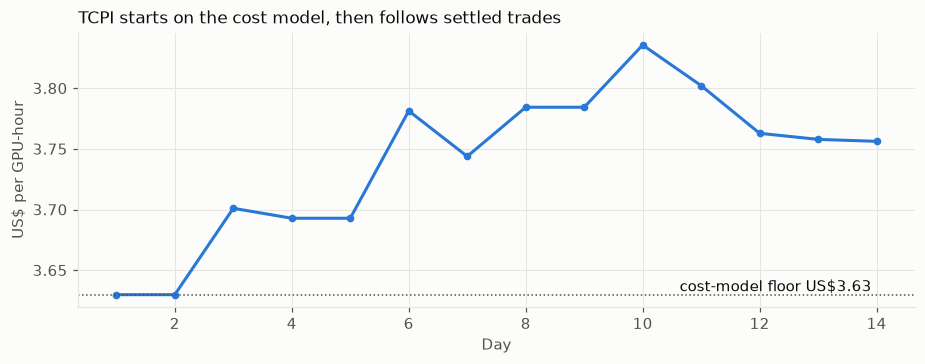

PASS  tripling the index in one print is refused -> DeviationTooLarge(200%)
PASS  a single federation node cannot publish -> QuorumNotMet
latestRoundData(): (14, 375640000, 1209600, 1209600, 14)
basis vs mock vendor index: US$-2.68/GPU-hr, or US$-1,959 per 730 GPU-hour contract
TCPI is physical, reserved-style Taiwan capacity; the vendor index is on-demand neocloud rental. That gap is the provenance spread.


In [19]:
PFLOPS_FP8, EFFICIENCY = 4.5, 0.60        # report section 3.3.1 for B200
PFLOP_HOURS_PER_GPU_HOUR = PFLOPS_FP8 * EFFICIENCY
THRESHOLD_VOLUME, WINDOW_DAYS, WINSOR_BAND = 500, 30, 0.10
CME_CONTRACT_GPU_HOURS = 730              # CME's filed GPU2 unit; CFTC review was pending on 5 Nov 2026

def weighted_median(trades):
    ordered = sorted(trades, key=lambda t: t[1])
    half, running = sum(q for q, _ in ordered) / 2, 0
    for i, (q, p) in enumerate(ordered):
        running += q
        if running == half and i + 1 < len(ordered): return (p + ordered[i + 1][1]) / 2
        if running >= half: return p

def winsorized_vwap(trades):
    '''Clamp each price to a band around the volume-weighted median, then average by volume.'''
    median = weighted_median(trades)
    low, high = median * (1 - WINSOR_BAND), median * (1 + WINSOR_BAND)
    return sum(q * min(max(p, low), high) for q, p in trades) / sum(q for q, _ in trades)

class TCPIEngine:
    def __init__(self, seed_price):
        self.seed_price, self.last, self.sunset = seed_price, None, False
        self.volumes = deque(maxlen=WINDOW_DAYS)
    def daily_print(self, trades):
        volume = sum(q for q, _ in trades)
        self.volumes.append(volume)
        self.sunset = self.sunset or sum(self.volumes) >= THRESHOLD_VOLUME    # one-way
        if not self.sunset: price, basis = self.seed_price, "COST-MODEL-SEED"
        elif trades: price, basis = winsorized_vwap(trades), "VWAP"
        else: price, basis = self.last, "CARRIED-FORWARD"
        self.last = price
        return round(price, 4), basis, volume

def inputs_hash(trades):
    '''Commitment to the exact trades behind a print, published with it.'''
    return keccak(text=json.dumps(sorted(trades), separators=(",", ":")))

class TCPIOracle:
    MAX_DEVIATION = 0.25
    def __init__(self, federation): self.federation, self.rounds = federation, []
    def publish(self, day, price, volume, sigs, emergency=False):
        digest = keccak(text=f"tcpi|{day}|{price}|{volume}|{emergency}")
        if not self.federation.verify(digest, sigs): raise Revert("QuorumNotMet")
        if self.rounds:
            if day <= self.rounds[-1]["day"]: raise Revert("DayNotIncreasing")
            move = abs(price / self.rounds[-1]["price"] - 1)
            if move > self.MAX_DEVIATION and not emergency: raise Revert(f"DeviationTooLarge({move:.0%})")
        self.rounds.append({"day": day, "price": price, "volume": volume})
    def latest_round_data(self):
        '''Same shape as Chainlink: (roundId, answer, startedAt, updatedAt, answeredInRound).'''
        n, r = len(self.rounds), self.rounds[-1]
        return (n, int(r["price"] * 1e8), r["day"] * DAY, r["day"] * DAY, n)

def signed_publish(oracle, day, price, volume, emergency=False):
    digest = keccak(text=f"tcpi|{day}|{price}|{volume}|{emergency}")
    oracle.publish(day, price, volume, federation.sign(digest), emergency)

engine, oracle = TCPIEngine(REFERENCE), TCPIOracle(federation)
rng = random.Random(5)
history, level = [], REFERENCE
for day in range(1, 15):
    level *= 1 + rng.uniform(-0.010, 0.016)
    count = 0 if day == 9 else 1 if day <= 2 else rng.randint(1, 4)   # a quiet start, and one day with no trades
    trades = [(rng.choice([96, 144, 192]), round(level * rng.uniform(0.99, 1.01), 3)) for _ in range(count)]
    price, basis, volume = engine.daily_print(trades)
    signed_publish(oracle, day, price, volume)
    history.append({"day": day, "TCPI US$/GPU-hr": price, "US$/PFLOP-hr": round(price / PFLOP_HOURS_PER_GPU_HOUR, 4), "volume": volume, "basis": basis})
frame = pd.DataFrame(history)
display(frame.tail(8))
check("COST-MODEL-SEED" in set(frame["basis"]) and "VWAP" in set(frame["basis"]), "the index started on the cost model and moved to VWAP")
check("COST-MODEL-SEED" not in set(frame["basis"].iloc[frame["basis"].tolist().index("VWAP"):]), "the sunset is one-way")
check(frame.loc[frame.day == 9, "basis"].iloc[0] == "CARRIED-FORWARD", "a day with no trades carries the last print forward")

honest = [(500, 3.70), (400, 3.72)]
wash = (100, 11.00)                       # a trade at 3x the market, 10% of the day's volume
plain = sum(q * p for q, p in honest + [wash]) / 1000
print(f"with a wash trade: plain VWAP US${plain:.2f}, winsorized US${winsorized_vwap(honest + [wash]):.2f}")
check(plain > 4.4 and winsorized_vwap(honest + [wash]) < 3.80, "winsorizing stops one wash trade moving the index")

day_trades = [(192, 3.70), (96, 3.72)]
published_hash = inputs_hash(day_trades)
check(inputs_hash(list(reversed(day_trades))) == published_hash, "an auditor rebuilds the same hash from the settled trades")
check(inputs_hash([(192, 3.71), (96, 3.72)]) != published_hash, "and any altered input is detected")

fig, ax = plt.subplots()
ax.plot(frame["day"], frame["TCPI US$/GPU-hr"], color=BLUE, marker="o", markersize=4, label="TCPI-B200 daily print")
ax.axhline(REFERENCE, color=MUTED, linewidth=1, linestyle=":")
ax.text(frame["day"].max(), REFERENCE, f"cost-model floor US${REFERENCE:.2f} ", ha="right", va="bottom", color=INK)
ax.set_xlabel("Day"); ax.set_ylabel("US$ per GPU-hour"); ax.set_title("TCPI starts on the cost model, then follows settled trades")
plt.tight_layout(); plt.show()

last = oracle.rounds[-1]
r = attempt(signed_publish, oracle, 99, round(last["price"] * 3, 4), 1000)
check(r.startswith("DeviationTooLarge"), f"tripling the index in one print is refused -> {r}")
digest = keccak(text=f"tcpi|100|{last['price']}|1|False")
r = attempt(oracle.publish, 100, last["price"], 1, federation.sign(digest, count=1))
check(r == "QuorumNotMet", f"a single federation node cannot publish -> {r}")
print("latestRoundData():", oracle.latest_round_data())
tcpi_now, vendor_now = oracle.rounds[-1]["price"], vendor.latest("SDB200RT")["value"]
print(f"basis vs mock vendor index: US${tcpi_now - vendor_now:+.2f}/GPU-hr, or US${(tcpi_now - vendor_now) * CME_CONTRACT_GPU_HOURS:+,.0f} per {CME_CONTRACT_GPU_HOURS} GPU-hour contract")
print("TCPI is physical, reserved-style Taiwan capacity; the vendor index is on-demand neocloud rental. That gap is the provenance spread.")

---
## 12. Petahour Labs: turning verified capacity into credit

**The legal point first.** Everything so far belongs to **Petahour**, the onshore Taiwan venue. A yield-bearing token issued by that entity risks Taiwan's 2020 FSC STO rules. So the report separates a second entity, **Petahour Labs**, offshore, which only *reads* Petahour's verified capacity and TCPI. In the full PoC this is visible in the code: Labs has its own deployer key and its own allow-list, and holds no role on any Petahour contract.

**Which offshore?** The 5 November evaluation narrows this. Singapore is a poor home: an entity serving only overseas customers needs a DTSP licence that MAS has said it will "generally" not issue. It points to Switzerland or Cayman/BVI. Taiwan's Virtual Asset Service Act (in force Q1 2027 at the earliest) has lending and custody licence types that may catch services to Taiwan users, and the sellers borrowing here are exactly that. So onboarding refuses retail and flags Taiwan institutions for a legal opinion. There is deliberately no native compute token.

**The stack:**

| Layer | Purpose |
|---|---|
| GPU Warehouse Receipt (ERC-721) | A claim on verified GPU-hours held under a bailment agreement. It cannot claim more hours than the host can physically produce |
| Wrapper (restricted ERC-20) | **Morpho Blue accepts ERC-20 collateral only**, so an ERC-721 cannot be posted directly. The report does not address this; the wrapper bridges it |
| Isolated lending market | Lend against receipts at 84% of TCPI x 62.5% LLTV: a 52.5% effective advance, close to the 55% cap on GMI Cloud's CTBC-led GPU loan. Both are settings real Morpho allows |
| Senior vault (ERC-4626) | Depositors earn up to 8% a year, ahead of first-loss holders |
| First-loss tranche | Junior capital, like USD.AI's sCHIP. It is lent alongside senior money, takes losses first and keeps what is left after senior yield |

**Stress test.** TCPI falls 60%. The position is liquidated, the collateral falls short, and the question is who pays.

*Simulated: this is plain arithmetic standing in for `contracts/labs/`. No real yield or token exists.*

In [20]:
class LendingPool:
    '''Senior and first-loss money lent together. First-loss capital is a recorded claim on the
    pool, not cash set aside, so a loss comes off that claim the moment it happens.'''
    def __init__(self, senior, first_loss):
        self.cash, self.lent, self.shares, self.first_loss = senior + first_loss, 0.0, senior, first_loss
    @property
    def assets(self): return self.cash + self.lent
    @property
    def senior_value(self): return self.assets - self.first_loss
    @property
    def share_price(self): return self.senior_value / self.shares
    def absorb(self, loss): self.first_loss -= min(loss, self.first_loss)

class Market:
    ORACLE_VALUE, LLTV = 0.84, 0.625       # 62.5% is an approved Morpho LLTV
    BONUS = 1 / (0.3 * LLTV + 0.7)         # Morpho's incentive at that LLTV, 12.68%
    def __init__(self, vault, oracle): self.vault, self.oracle, self.debt, self.collateral = vault, oracle, 0.0, 0.0
    def price(self): return self.oracle.latest_round_data()[1] / 1e8
    def max_borrow(self): return self.collateral * self.price() * self.ORACLE_VALUE * self.LLTV
    def borrow(self, amount):
        if self.debt + amount > self.max_borrow(): raise Revert("InsufficientCollateral")
        self.debt += amount; self.vault.cash -= amount; self.vault.lent += amount
    def healthy(self): return self.debt <= self.max_borrow()
    def liquidate(self):
        if self.healthy(): raise Revert("PositionHealthy")
        seized_value = self.collateral * self.price() * self.ORACLE_VALUE
        repaid = min(self.debt, seized_value / self.BONUS)
        bad_debt = self.debt - repaid
        self.vault.cash += repaid; self.vault.lent -= repaid + bad_debt
        self.vault.absorb(bad_debt)
        self.debt, self.collateral = 0.0, 0.0
        return repaid, bad_debt

def physical_limit(gpus, hours_until_expiry): return gpus * hours_until_expiry

HOURS_HELD = 1_000
check(HOURS_HELD <= physical_limit(8, 20 * 24), f"the receipt's {HOURS_HELD} GPU-hours fit inside what 8 GPUs can produce in 20 days")
check(50_000 > physical_limit(8, 20 * 24), "a receipt for 50,000 GPU-hours on that host would be refused")

labs_registry = MemberRegistry()      # a separate allow-list, under a separate admin
check(registry.is_eligible(buyer.address) and not labs_registry.is_eligible(buyer.address), "a Petahour member is not automatically a Petahour Labs member")

def labs_policy(investor_class, country):
    if investor_class != "institutional": return "REFUSED: institutional only"
    return "LEGAL-REVIEW: Taiwan user, Virtual Asset Service Act" if country == "TW" else "CLEAR"
check(labs_policy("retail", "TW").startswith("REFUSED"), "Petahour Labs refuses retail")
check(labs_policy("institutional", "TW").startswith("LEGAL-REVIEW"), "a Taiwan institution is flagged for legal review, not silently admitted")

vault = LendingPool(20_000.0, 3_000.0)
market = Market(vault, oracle)
market.collateral = HOURS_HELD
borrow_amount = market.max_borrow() * 0.98
market.borrow(borrow_amount)
print(f"TCPI US${market.price():.4f}: {HOURS_HELD:,} GPU-hours supports {usd(market.max_borrow())}; borrowed {usd(borrow_amount)}")
r = attempt(market.liquidate)
check(r == "PositionHealthy", f"a healthy position cannot be liquidated -> {r}")

stages = [("Before crash", vault.senior_value, vault.first_loss)]
crash_price = round(market.price() * 0.40, 4)
r = attempt(signed_publish, oracle, 200, crash_price, 1000)
check(r.startswith("DeviationTooLarge"), f"a 60% fall needs an emergency flag -> {r}")
signed_publish(oracle, 200, crash_price, 1000, emergency=True)
check(not market.healthy(), f"TCPI falls to US${crash_price}: the position is under water")

repaid, bad_debt = market.liquidate()
print(f"liquidation repaid {usd(repaid)}, bad debt {usd(bad_debt)}")
stages.append(("After liquidation", vault.senior_value, vault.first_loss))
check(abs(vault.share_price - 1) < 1e-9, "senior depositors are whole, with nobody having to act")
check(vault.first_loss == 3_000.0 - bad_debt, f"the junior tranche took the {usd(bad_debt)} loss at once")
print(f"the crash cost {bad_debt / borrow_amount:.0%} of the loan; this pool copes because the loan is small against it")

table([{"Stage": name, "Senior value": usd(senior_value), "First-loss claim": usd(claim)} for name, senior_value, claim in stages])

PASS  the receipt's 1000 GPU-hours fit inside what 8 GPUs can produce in 20 days
PASS  a receipt for 50,000 GPU-hours on that host would be refused
PASS  a Petahour member is not automatically a Petahour Labs member
PASS  Petahour Labs refuses retail
PASS  a Taiwan institution is flagged for legal review, not silently admitted
TCPI US$3.7564: 1,000 GPU-hours supports 1,972.11; borrowed 1,932.67
PASS  a healthy position cannot be liquidated -> PositionHealthy
PASS  a 60% fall needs an emergency flag -> DeviationTooLarge(60%)
PASS  TCPI falls to US$1.5026: the position is under water
liquidation repaid 1,120.19, bad debt 812.48
PASS  senior depositors are whole, with nobody having to act
PASS  the junior tranche took the 812.48 loss at once
the crash cost 42% of the loan; this pool copes because the loan is small against it


,Stage,Senior value,First-loss claim
0,Before crash,"20,000.00","3,000.00"
1,After liquidation,"20,000.00","2,187.52"


### How Labs earns

Labs charges three things, taken from the 6 November financial model:

- **Curator fee.** 10% of the interest the vault earns, paid in vault shares.
- **Origination fee.** 0.5% of new loans, out of the amount drawn. A borrower rolling a loan back up to a balance it has already paid on pays nothing, which suits rolling 12-month receipts.
- **Data licence to Petahour.** 0.10% a year on average loans, the rate any lender pays. It is measured over time, and anyone can trigger the payment, so Petahour needs no role at Labs. Labs cannot take money out while the licence is unpaid.

**The trap.** After a default that seniors bear, interest first has to refill the hole. A fee on "any increase in assets" would pay the curator 10% of that refilling. The vault uses a high-water mark instead: the curator is paid only on gains above the mark, and a loss seniors bear never lowers it. A loss first-loss capital takes does come off the mark, because that capital has left the books with it.

*Simulated: this is arithmetic standing in for `ComputeCreditVault`, `IsolatedLendingMarket` and `LabsTreasury`.*

In [21]:
class CuratorFee:
    '''The vault's high-water mark: paid on gains above it. Only capital that left lowers it.'''
    RATE = 0.10
    def __init__(self, assets): self.mark = assets
    def write_off(self, covered): self.mark -= covered
    def accrue(self, assets):
        if assets <= self.mark: return 0.0
        fee = (assets - self.mark) * self.RATE
        self.mark = assets
        return fee

fee = CuratorFee(20_000.0)
interest = 1_000 * 0.12
check(abs(fee.accrue(20_000.0 + interest) - 12.0) < 1e-9, "the curator earns 12.00, 10% of 120.00 of interest")
assets = 20_000.0 + interest - bad_debt
fee.write_off(bad_debt)
check(fee.accrue(assets) == 0.0, f"a {usd(bad_debt)} loss taken by first-loss capital pays the curator nothing")
check(abs(fee.accrue(assets + interest) - 12.0) < 1e-9, "and the next interest pays its usual 12.00")

fee = CuratorFee(20_000.0)
check(fee.accrue(19_500.0) == 0.0, "a 500 loss that seniors bear leaves the mark where it was")
check(fee.accrue(20_000.0) == 0.0, "interest that only refills the hole is not income")
check(abs(fee.accrue(20_100.0) - 10.0) < 1e-9, "the curator earns again only above the mark")

def origination_fee(new_balance, paid_up_to, drawn, rate=0.005):
    growth = max(0.0, new_balance - paid_up_to)
    return min(growth, drawn) * rate

check(origination_fee(1_000, 0, 1_000) == 5.0, "a new 1,000 loan pays 5.00 of origination")
check(origination_fee(1_000, 1_000, 1_000) == 0.0, "rolling the same 1,000 pays nothing")
check(origination_fee(1_200, 1_000, 1_200) == 1.0, "growing it to 1,200 pays on the extra 200 only")

balances = [(1_000, 73), (0, 73), (1_500, 73)]        # loan balance and days held
licence = sum(balance * days / 365 * 0.001 for balance, days in balances)
check(abs(licence - 0.50) < 1e-9, f"the licence follows the balance over time: {licence:.2f} on those three periods")

PASS  the curator earns 12.00, 10% of 120.00 of interest
PASS  a 812.48 loss taken by first-loss capital pays the curator nothing
PASS  and the next interest pays its usual 12.00
PASS  a 500 loss that seniors bear leaves the mark where it was
PASS  interest that only refills the hole is not income
PASS  the curator earns again only above the mark
PASS  a new 1,000 loan pays 5.00 of origination
PASS  rolling the same 1,000 pays nothing
PASS  growing it to 1,200 pays on the extra 200 only
PASS  the licence follows the balance over time: 0.50 on those three periods


### What first-loss capital earns

First-loss capital is only worth holding if it is paid for the risk. The financial model pays it what is left of the interest once everyone ahead of it has been paid, in this order:

1. **Curator.** 10% of interest.
2. **Credit losses.** First-loss capital takes these first.
3. **Senior investors.** 8% a year on their capital.
4. **First-loss holders.** The rest.

That return needs first-loss money to be **lent**, not held as cash. Loans are funded 87% senior and 13% first-loss, so a dollar of first-loss capital earns interest and then collects the spread between what borrowers pay and what seniors receive. Labs itself holds a quarter of the tranche, so it takes a quarter of this return.

**Two consequences.** Below the 8% hurdle first-loss capital earns nothing, because it is paid last: seniors keep what there is, and a thin period has to be made up before first-loss earns again. And it pays only on a well-used pool. About 64% of the pool must be lent before there is anything left at all.

*Simulated: this is arithmetic standing in for `ComputeCreditVault.waterfall`. The Solidity tests reproduce the same three cases on-chain.*

PASS  Base (1% losses): first-loss earns 21.8%, the financial model's figure
PASS  Bear (3%): first-loss earns 6.5%, the financial model's figure
PASS  Bull (0.5%): first-loss earns 25.7%, the financial model's figure
PASS  seniors get exactly their 8% on 8,700 of capital: 696.00
PASS  Labs' quarter of the 284.00 left over is 71.00
PASS  with half the pool lent, seniors take everything and first-loss earns nothing
PASS  first-loss earns only once 64% of the pool is lent


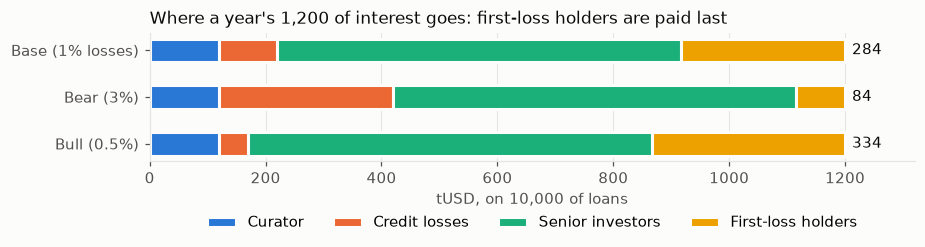

In [22]:
LOAN_RATE, CURATOR_SHARE, SENIOR_YIELD, FIRST_LOSS_SHARE, LABS_SHARE = 0.12, 0.10, 0.08, 0.13, 0.25

def year_of_waterfall(loans, loss_rate, lent=1.0):
    '''One year on a pool of `loans` dollars, of which `lent` is out earning interest.'''
    first_loss, senior = loans * FIRST_LOSS_SHARE, loans * (1 - FIRST_LOSS_SHARE)
    interest = loans * lent * LOAN_RATE
    curator, losses = interest * CURATOR_SHARE, loans * loss_rate
    to_senior = min(interest - curator, senior * SENIOR_YIELD)
    left = interest - curator - to_senior
    return {"Curator": curator, "Credit losses": losses, "Senior investors": to_senior,
            "First-loss holders": left - losses, "first_loss_capital": first_loss}

cases = {"Base (1% losses)": 0.01, "Bear (3%)": 0.03, "Bull (0.5%)": 0.005}
expected = {"Base (1% losses)": 21.8, "Bear (3%)": 6.5, "Bull (0.5%)": 25.7}
years = {name: year_of_waterfall(10_000, loss) for name, loss in cases.items()}
for name, year in years.items():
    earned = year["First-loss holders"] / year["first_loss_capital"] * 100
    check(round(earned, 1) == expected[name], f"{name}: first-loss earns {earned:.1f}%, the financial model's figure")

base = years["Base (1% losses)"]
check(abs(base["Senior investors"] - 696) < 1e-9, "seniors get exactly their 8% on 8,700 of capital: 696.00")
check(abs(base["First-loss holders"] * LABS_SHARE - 71) < 1e-9, "Labs' quarter of the 284.00 left over is 71.00")

half_lent = year_of_waterfall(10_000, 0.0, lent=0.5)
check(half_lent["First-loss holders"] == 0, "with half the pool lent, seniors take everything and first-loss earns nothing")
hurdle = (1 - FIRST_LOSS_SHARE) * SENIOR_YIELD / (LOAN_RATE * (1 - CURATOR_SHARE))
check(0.64 < hurdle < 0.65, f"first-loss earns only once {hurdle:.0%} of the pool is lent")

names = list(years)
parts = [("Curator", BLUE), ("Credit losses", ORANGE), ("Senior investors", AQUA), ("First-loss holders", YELLOW)]
fig, ax = plt.subplots(figsize=(8.5, 2.6))
left = np.zeros(len(names))
for part, colour in parts:
    values = np.array([years[n][part] for n in names])
    ax.barh(names, values, left=left, height=0.5, color=colour, edgecolor="#fcfcfb", linewidth=2, label=part)
    for i, v in enumerate(values):
        if part == "First-loss holders": ax.text(left[i] + v + 12, i, f"{v:,.0f}", va="center", color=INK)
    left += values
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, 1_320); ax.set_xlabel("tUSD, on 10,000 of loans")
ax.set_title("Where a year's 1,200 of interest goes: first-loss holders are paid last")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.32))
plt.tight_layout(); plt.show()

### How big a crash can 13% take?

The stress test above looks reassuring, but its one loan is small against the pool: 3,000 of first-loss capital stands behind a loan of about 1,900. At the model's 13% of loans, with the whole pool lent, the same crash is a different story.

The table assumes the harshest case: every loan drawn to 98% of its limit, and all of them liquidated at once at the oracle's price. A liquidator pays the oracle's value less Morpho's incentive, about 74.5% of index, so the loss is larger than the fall in collateral alone.

*Simulated: arithmetic standing in for `IsolatedLendingMarket.liquidate`. A Solidity test runs the 60% case on-chain.*

,TCPI fall,Loss on loans,First-loss left,Senior loss
0,25%,0.0%,100%,0.0%
1,31%,0.0%,100%,0.0%
2,35%,5.8%,55%,0.0%
3,40%,13.1%,0%,0.1%
4,50%,27.6%,0%,16.7%
5,60%,42.0%,0%,33.4%


PASS  losses start once TCPI falls 31%
PASS  at 13%, first-loss capital is gone once TCPI falls 40%
PASS  the model's 3% bear case equals a 33% fall hitting every loan
PASS  a 60% fall on a full book costs seniors 33.4%


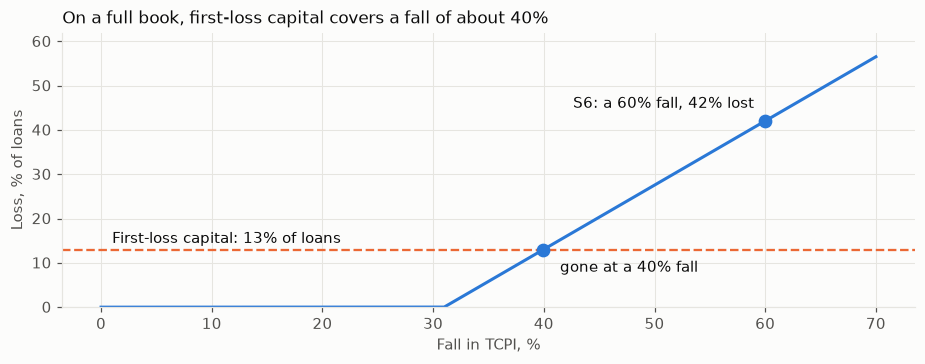

In [23]:
ADVANCE = 0.98 * Market.ORACLE_VALUE * Market.LLTV

def crash_on_a_full_book(fall):
    '''Loss as a share of loans if every loan is at 98% of its limit and all are liquidated.'''
    recovered = (1 - fall) * Market.ORACLE_VALUE / Market.BONUS
    loss = max(0.0, 1 - recovered / ADVANCE)
    return {"TCPI fall": f"{fall:.0%}", "Loss on loans": f"{loss:.1%}",
            "First-loss left": f"{max(0.0, FIRST_LOSS_SHARE - loss) / FIRST_LOSS_SHARE:.0%}",
            "Senior loss": f"{max(0.0, loss - FIRST_LOSS_SHARE) / (1 - FIRST_LOSS_SHARE):.1%}"}

table([crash_on_a_full_book(f) for f in (0.25, 0.31, 0.35, 0.40, 0.50, 0.60)])

first_bad_debt = 1 - ADVANCE * Market.BONUS / Market.ORACLE_VALUE
first_loss_gone = 1 - (1 - FIRST_LOSS_SHARE) * ADVANCE * Market.BONUS / Market.ORACLE_VALUE
bear_case = 1 - (1 - 0.03) * ADVANCE * Market.BONUS / Market.ORACLE_VALUE
check(0.30 < first_bad_debt < 0.32, f"losses start once TCPI falls {first_bad_debt:.0%}")
check(0.39 < first_loss_gone < 0.41, f"at 13%, first-loss capital is gone once TCPI falls {first_loss_gone:.0%}")
check(0.32 < bear_case < 0.34, f"the model's 3% bear case equals a {bear_case:.0%} fall hitting every loan")
sixty = crash_on_a_full_book(0.60)
check(sixty["Loss on loans"] == "42.0%" and sixty["Senior loss"] == "33.4%", f"a 60% fall on a full book costs seniors {sixty['Senior loss']}")

falls = np.linspace(0, 0.70, 141)
losses = [max(0.0, 1 - (1 - f) * Market.ORACLE_VALUE / Market.BONUS / ADVANCE) * 100 for f in falls]
fig, ax = plt.subplots()
ax.plot(falls * 100, losses, color=BLUE)
ax.axhline(FIRST_LOSS_SHARE * 100, color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(1, FIRST_LOSS_SHARE * 100 + 1.5, "First-loss capital: 13% of loans", color=INK)
ax.plot([first_loss_gone * 100], [FIRST_LOSS_SHARE * 100], "o", color=BLUE, markersize=8)
ax.text(first_loss_gone * 100 + 1.5, FIRST_LOSS_SHARE * 100 - 5, f"gone at a {first_loss_gone:.0%} fall", color=INK)
s6_loss = float(sixty["Loss on loans"].rstrip("%"))
ax.plot([60], [s6_loss], "o", color=BLUE, markersize=8)
ax.text(59, s6_loss + 3, f"S6: a 60% fall, {s6_loss:.0f}% lost", ha="right", color=INK)
ax.set_xlabel("Fall in TCPI, %"); ax.set_ylabel("Loss, % of loans"); ax.set_ylim(0, 62)
ax.set_title("On a full book, first-loss capital covers a fall of about 40%")
plt.tight_layout(); plt.show()

### Why 84% and 62.5%

The same 52.5% advance can be split between the oracle and the loan-to-value in several ways, and the split matters. What the oracle counts is also what a liquidator pays, so a higher oracle value means more of each loan comes back in a crash.

Real Morpho narrows the choice. It allows only approved LLTVs, and it sets the liquidation incentive from the LLTV rather than letting a market choose. Lower LLTVs carry a larger incentive, but the higher oracle value more than makes up for it.

*Simulated: arithmetic standing in for Morpho's rules. Solidity tests confirm the 62.5% figures on-chain, and the demo reads the settings back from the chain.*

In [24]:
def split_on_morpho(lltv):
    '''Keeps the 52.5% advance where an approved LLTV allows it, and shows what 13% then covers.'''
    advance = min(0.525, lltv)
    oracle_value = advance / lltv
    incentive = min(1.15, 1 / (0.3 * lltv + 0.7))
    recovered = oracle_value / incentive
    covers = 1 - (1 - FIRST_LOSS_SHARE) * 0.98 * advance / recovered
    return {"LLTV": f"{lltv:.1%}", "Advance": f"{advance:.1%}", "Oracle counts": f"{oracle_value:.1%}",
            "Incentive": f"{incentive - 1:.1%}", "Liquidator pays, of index": f"{recovered:.1%}", "13% covers a fall of": f"{covers:.1%}"}

splits = {lltv: split_on_morpho(lltv) for lltv in (0.385, 0.625, 0.77, 0.86)}
table(list(splits.values()))
check(splits[0.625]["13% covers a fall of"] == "40.0%", "at 62.5%, the plan's 13% covers about a 40% fall")
check(splits[0.77]["13% covers a fall of"] == "29.5%", "at 77%, the nearest approved value to 75%, it covers only 29.5%")
check(splits[0.385]["Advance"] == "38.5%", "38.5% survives more, but only by lending less: the advance cannot stay at 52.5%")
check(Market.ORACLE_VALUE * Market.LLTV == 0.525, "the settings in use keep the 52.5% advance")

,LLTV,Advance,Oracle counts,Incentive,"Liquidator pays, of index",13% covers a fall of
0,38.5%,38.5%,100.0%,15.0%,87.0%,62.3%
1,62.5%,52.5%,84.0%,12.7%,74.6%,40.0%
2,77.0%,52.5%,68.2%,7.4%,63.5%,29.5%
3,86.0%,52.5%,61.0%,4.4%,58.5%,23.5%


PASS  at 62.5%, the plan's 13% covers about a 40% fall
PASS  at 77%, the nearest approved value to 75%, it covers only 29.5%
PASS  38.5% survives more, but only by lending less: the advance cannot stay at 52.5%
PASS  the settings in use keep the 52.5% advance


---
## 13. How this maps to the full PoC

| Notebook | Full PoC (`petahour-poc/`) |
|---|---|
| `MiniChain` | Anvil, Arbitrum Sepolia or Base Sepolia (a real EVM) |
| `Escrow`, `DefaultFund` | `contracts/core/DvPEscrow.sol`, `DefaultFund.sol` |
| `MemberRegistry`, `Federation` | `contracts/core/MemberRegistry.sol`, `Federation.sol` |
| Passport dictionary | `contracts/core/ComputePassport.sol` (non-transferable ERC-721) |
| `allocated` dictionary | `contracts/core/CapacityPool.sol` (bit-packed hourly allocation) |
| `MockNRAS` | `petahour/mocks/server.py`, an HTTP service with JWKS |
| Logistic regression, 3 features | MLP (6 inputs, 4 ReLU units) in `circuits/delivery_score.circom` |
| Toy MiMC sponge | Poseidon |
| Python Groth16 | `snarkjs`, and the generated `Groth16Verifier.sol` on-chain (about 320,000 gas) |
| `TCPIOracle` | `contracts/core/TCPIOracle.sol` with `TCPIFeed` (Chainlink-shaped), plus an on-chain inputs hash per print |
| `CuratorFee`, `origination_fee`, the licence sum | `contracts/labs/ComputeCreditVault.sol`, `IsolatedLendingMarket.sol` and `LabsTreasury.sol` |
| `Market`, `LendingPool` | `contracts/labs/` (real ERC-721, ERC-20 and ERC-4626) |
| `year_of_waterfall` | `ComputeCreditVault.waterfall`, which runs on every read rather than once a year |

**What neither version proves.** No real GPU was attested, no real money moved, and no legal structure was tested. No regulatory position here is settled: the venue's route is an FSC classification inquiry plus voluntary MOEA/NSTC endorsement, not statutory oversight. Hardware attestation is simulated until PoC-1 runs on lab-controlled nodes. The model's scores say nothing about real fleets. Treat this as evidence that the mechanisms fit together, not that the business or the regulatory position is settled.

In [25]:
print(f"{sum(CHECKS)} of {len(CHECKS)} checks passed")
assert all(CHECKS)

102 of 102 checks passed
